# AIoT 作業二：洪水機率預測 (Flood Probability Prediction)

- **學生學號**：7115064011
- **分析方法**：CRISP-DM (Cross-Industry Standard Process for Data Mining) 資料探勘跨產業標準流程
- **執行階段**：
  - Phase 1 - Business Understanding（商業理解）
  - Phase 2 - Data Understanding（資料理解）
  - Phase 3 - Data Preparation（資料準備與特徵選擇）
  - Phase 4 - Modeling（模型建立與比較）
  - Phase 5 - Evaluation（模型評估與殘差診斷）
  - Phase 6 - Deployment（模型部署與應用）

--- 
## 1. 商業理解 (Business Understanding)

> **重要加註**：本資料為 Kaggle Playground Series S4E5 合成資料，模型僅作方法示範，不代表台灣實際狀況。

### 1.1 預測目的 (Purpose & Objective)
洪水是全球最普遍且破壞性極高的自然災害之一，對人民生命、基礎建設及農業經濟造成嚴重衝擊。本專案之核心目標是**基於 20 項環境、地理、氣象與人為治理特徵，建立高精準度的迴歸模型，預測特定區域的洪水發生機率（Flood Probability）**。
透過準確預測洪水機率，相關單位可在極端氣候事件發生前及早部署防洪資源、擬定精準防災方案，從「災後被動搶修」轉型為「災前主動預警與減災」。

### 1.2 目標使用者與利害關係人 (Target Users & Stakeholders)
1. **水利署與防汛決策部門 (Water Resources & Flood Control Agencies)**：
   - 依據預測之洪水風險機率，提前規劃水庫調節性放水、水門啟閉與抽水機預先調度。
2. **中央與地方災害應變中心 (Disaster Response & Emergency Management)**：
   - 辨識高潛勢淹水熱區，提前規劃居民疏散撤離路線、收容所安置與警報發布機制。
3. **都市規劃與公共工程部門 (Urban Planning & Public Works)**：
   - 評估區域排水容量、土地開發利用管制與老化基礎設施之翻新優先順序。
4. **保險業者與金融機構 (Insurance & Financial Institutions)**：
   - 評估各區域天災風險溢價，提供精準之水災保險定價與企業營運中斷風險評估。

### 1.3 成功標準 (Success Criteria)
1. **機器學習技術指標 (Technical Metrics)**：
   - **決定係數 ($R^2$ Score)**：目標達成 $R^2 \ge 0.84$ 以上（能高度解釋目標變數的變異量）。
   - **誤差指標 (RMSE / MAE)**：均方根誤差與平均絕對誤差越小越好，以確保機率估計值之穩定性與一致性。
2. **商業與營運應用效益 (Business & Operational Metrics)**：
   - **高風險區域之預測誤差**：降低高風險區域之預測誤差，確保極端風險估計之準確性，提供可靠的防汛應變決策支援。
   - **特徵可解釋性 (Interpretability)**：明確識別出對洪水機率影響最顯著的關鍵因子，為公共治理與水土保持提供具體決策依據。

--- 
## 2. 資料理解 (Data Understanding)

本階段著重於探索與分析資料集之結構、型態、品質與統計特性。
資料集採用 `data/train.csv`，實際輸出為 1,117,957 筆觀測值，包含 `id`、20 個環境/治理相關數值特徵，以及預測目標 `FloodProbability`。

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 抑制警告訊息
warnings.filterwarnings('ignore')

# 設定繪圖風格與英文字型顯示
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# 設定資料載入路徑（相容 notebooks/ 或專案根目錄）
DATA_PATH = '../data/train.csv' if os.path.exists('../data/train.csv') else 'data/train.csv'
print(f"Data file path: {DATA_PATH}")

Data file path: ../data/train.csv


In [2]:
# 載入訓練資料集
df = pd.read_csv(DATA_PATH)
print("Data loaded successfully into pandas DataFrame!")

Data loaded successfully into pandas DataFrame!


### 2.1 資料形狀、欄位清單與資料型態 (Data Shape, Columns, Data Types)

In [3]:
# 檢視資料集維度與記憶體使用量
num_rows, num_cols = df.shape
mem_usage = df.memory_usage().sum() / (1024 ** 2)

print(f"Total Rows (Observations): {num_rows:,}")
print(f"Total Columns (Variables): {num_cols}")
print(f"Memory Usage: {mem_usage:.2f} MB\n")

# 預覽前 5 筆資料
df.head()

Total Rows (Observations): 1,117,957
Total Columns (Variables): 22
Memory Usage: 187.65 MB



,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,0,5,8,5,8,6,4,4,3,3,...,5,3,3,5,4,7,5,7,3,0.445
1,1,6,7,4,4,8,8,3,5,4,...,7,2,0,3,5,3,3,4,3,0.450
2,2,6,5,6,7,3,7,1,5,4,...,7,3,7,5,6,8,2,3,3,0.530
3,3,3,4,6,5,4,8,4,7,6,...,2,4,7,4,4,6,5,7,5,0.535
4,4,5,3,2,6,4,4,3,3,3,...,2,2,6,6,4,1,2,3,5,0.415


In [4]:
# 欄位清單與資料型態摘要表
col_summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.notnull().sum(),
    'Null Count': df.isnull().sum(),
    'Unique Values': df.nunique()
}).reset_index(drop=True)

print("=== Column List & Data Types Summary ===")
display(col_summary)

print("\n=== DataFrame Info ===")
df.info(show_counts=True)

=== Column List & Data Types Summary ===


,Column Name,Data Type,Non-Null Count,Null Count,Unique Values
0,id,int64,1117957,0,1117957
1,MonsoonIntensity,int64,1117957,0,17
2,TopographyDrainage,int64,1117957,0,19
3,RiverManagement,int64,1117957,0,17
4,Deforestation,int64,1117957,0,18
5,Urbanization,int64,1117957,0,18
6,ClimateChange,int64,1117957,0,18
7,DamsQuality,int64,1117957,0,17
8,Siltation,int64,1117957,0,17
9,AgriculturalPractices,int64,1117957,0,17



=== DataFrame Info ===
<class 'pandas.DataFrame'>
RangeIndex: 1117957 entries, 0 to 1117956
Data columns (total 22 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   id                               1117957 non-null  int64  
 1   MonsoonIntensity                 1117957 non-null  int64  
 2   TopographyDrainage               1117957 non-null  int64  
 3   RiverManagement                  1117957 non-null  int64  
 4   Deforestation                    1117957 non-null  int64  
 5   Urbanization                     1117957 non-null  int64  
 6   ClimateChange                    1117957 non-null  int64  
 7   DamsQuality                      1117957 non-null  int64  
 8   Siltation                        1117957 non-null  int64  
 9   AgriculturalPractices            1117957 non-null  int64  
 10  Encroachments                    1117957 non-null  int64  
 11  IneffectiveDisasterPreparedness  1117

### 2.2 缺失值檢查 (Missing Values Inspection)

In [5]:
# 檢查每個欄位的缺失值數量與比例
missing_val = df.isnull().sum()
total_missing = missing_val.sum()

print(f"Total Missing Values across all cells: {total_missing}")
if total_missing == 0:
    print("Status: Excellent! There are NO missing values in the entire dataset.")
else:
    missing_summary = missing_val[missing_val > 0].to_frame(name='Missing Count')
    missing_summary['Missing Percentage (%)'] = (missing_summary['Missing Count'] / len(df)) * 100
    display(missing_summary)

Total Missing Values across all cells: 0
Status: Excellent! There are NO missing values in the entire dataset.


### 2.3 敘述統計 (Descriptive Statistics)

針對 20 個特徵及目標變數進行集中趨勢、分散程度與分佈型態（偏態與峰度）之統計量分析。

In [6]:
# 排除流水號 id 欄位進行統計分析
analysis_cols = [col for col in df.columns if col != 'id']

desc_stats = df[analysis_cols].describe().T
desc_stats['median'] = df[analysis_cols].median()
desc_stats['skewness'] = df[analysis_cols].skew()
desc_stats['kurtosis'] = df[analysis_cols].kurt()

# 重新排序列順序以便閱讀
desc_summary = desc_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness', 'kurtosis']]

print("=== Descriptive Statistics for Features and Target ===")
display(desc_summary.round(4))

=== Descriptive Statistics for Features and Target ===


,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
MonsoonIntensity,1117957.0,4.9215,2.0564,0.000,3.00,5.000,6.00,16.000,0.4445,0.3412
TopographyDrainage,1117957.0,4.9267,2.0939,0.000,3.00,5.000,6.00,18.000,0.4587,0.2384
RiverManagement,1117957.0,4.9553,2.0722,0.000,4.00,5.000,6.00,16.000,0.4265,0.2242
Deforestation,1117957.0,4.9422,2.0517,0.000,4.00,5.000,6.00,17.000,0.4343,0.2751
Urbanization,1117957.0,4.9425,2.0834,0.000,3.00,5.000,6.00,17.000,0.4422,0.2483
ClimateChange,1117957.0,4.9341,2.0577,0.000,3.00,5.000,6.00,17.000,0.4294,0.2413
DamsQuality,1117957.0,4.9559,2.0831,0.000,4.00,5.000,6.00,16.000,0.4414,0.2621
Siltation,1117957.0,4.9278,2.0660,0.000,3.00,5.000,6.00,16.000,0.4492,0.2871
AgriculturalPractices,1117957.0,4.9426,2.0685,0.000,3.00,5.000,6.00,16.000,0.4211,0.2141
Encroachments,1117957.0,4.9492,2.0833,0.000,4.00,5.000,6.00,18.000,0.4636,0.2666


### 2.4 目標變數 `FloodProbability` 的分佈圖 (Target Variable Distribution)

分析預測目標 `FloodProbability` 的數值分佈型態、對稱性以及是否存在離群極端值。

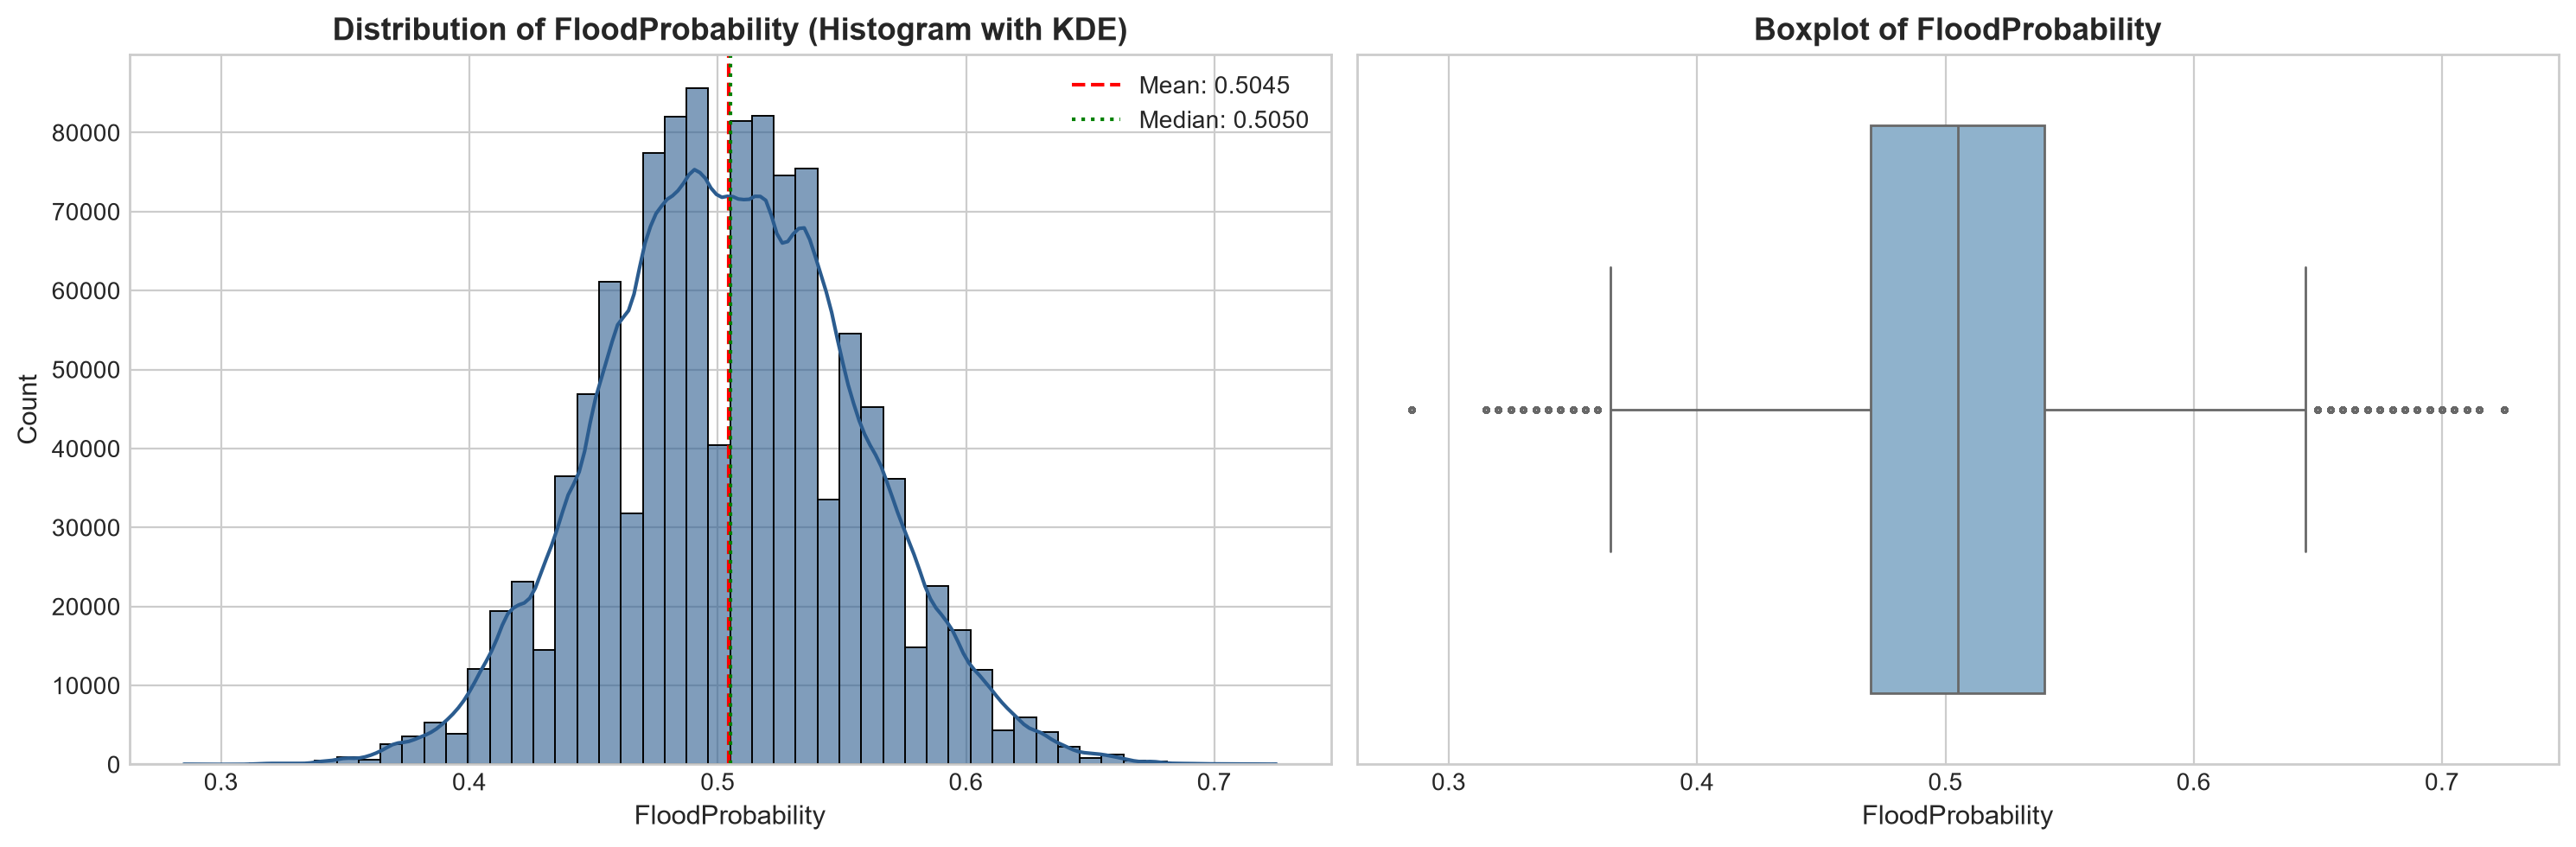

Target Summary Statistics:
- Mean: 0.5045
- Std Dev: 0.0510
- Median: 0.5050
- Min: 0.2850, Max: 0.7250
- Skewness: 0.0472 (Near zero: Highly symmetric)
- Kurtosis: -0.0396


In [7]:
target_col = 'FloodProbability'

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. 直方圖與 KDE 密度分佈曲線
sns.histplot(df[target_col], bins=50, kde=True, ax=axes[0], color='#2b5c8f', edgecolor='black', alpha=0.6)
axes[0].set_title('Distribution of FloodProbability (Histogram with KDE)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('FloodProbability', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].axvline(df[target_col].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df[target_col].mean():.4f}")
axes[0].axvline(df[target_col].median(), color='green', linestyle=':', linewidth=1.5, label=f"Median: {df[target_col].median():.4f}")
axes[0].legend(fontsize=10)

# 2. 箱形圖 (Boxplot) 檢視離群值與分位數
sns.boxplot(x=df[target_col], ax=axes[1], color='#85b4d6', fliersize=2)
axes[1].set_title('Boxplot of FloodProbability', fontsize=13, fontweight='bold')
axes[1].set_xlabel('FloodProbability', fontsize=11)

plt.tight_layout()
plt.show()

print(f"Target Summary Statistics:")
print(f"- Mean: {df[target_col].mean():.4f}")
print(f"- Std Dev: {df[target_col].std():.4f}")
print(f"- Median: {df[target_col].median():.4f}")
print(f"- Min: {df[target_col].min():.4f}, Max: {df[target_col].max():.4f}")
print(f"- Skewness: {df[target_col].skew():.4f} (Near zero: Highly symmetric)")
print(f"- Kurtosis: {df[target_col].kurt():.4f}")

### 2.5 20 個特徵的相關係數熱圖 (Correlation Heatmap of 20 Features)

檢視 20 個環境與人為特徵彼此間的 Pearson 相關係數，評估特徵間是否存在多重共線性 (Multicollinearity) 現象。

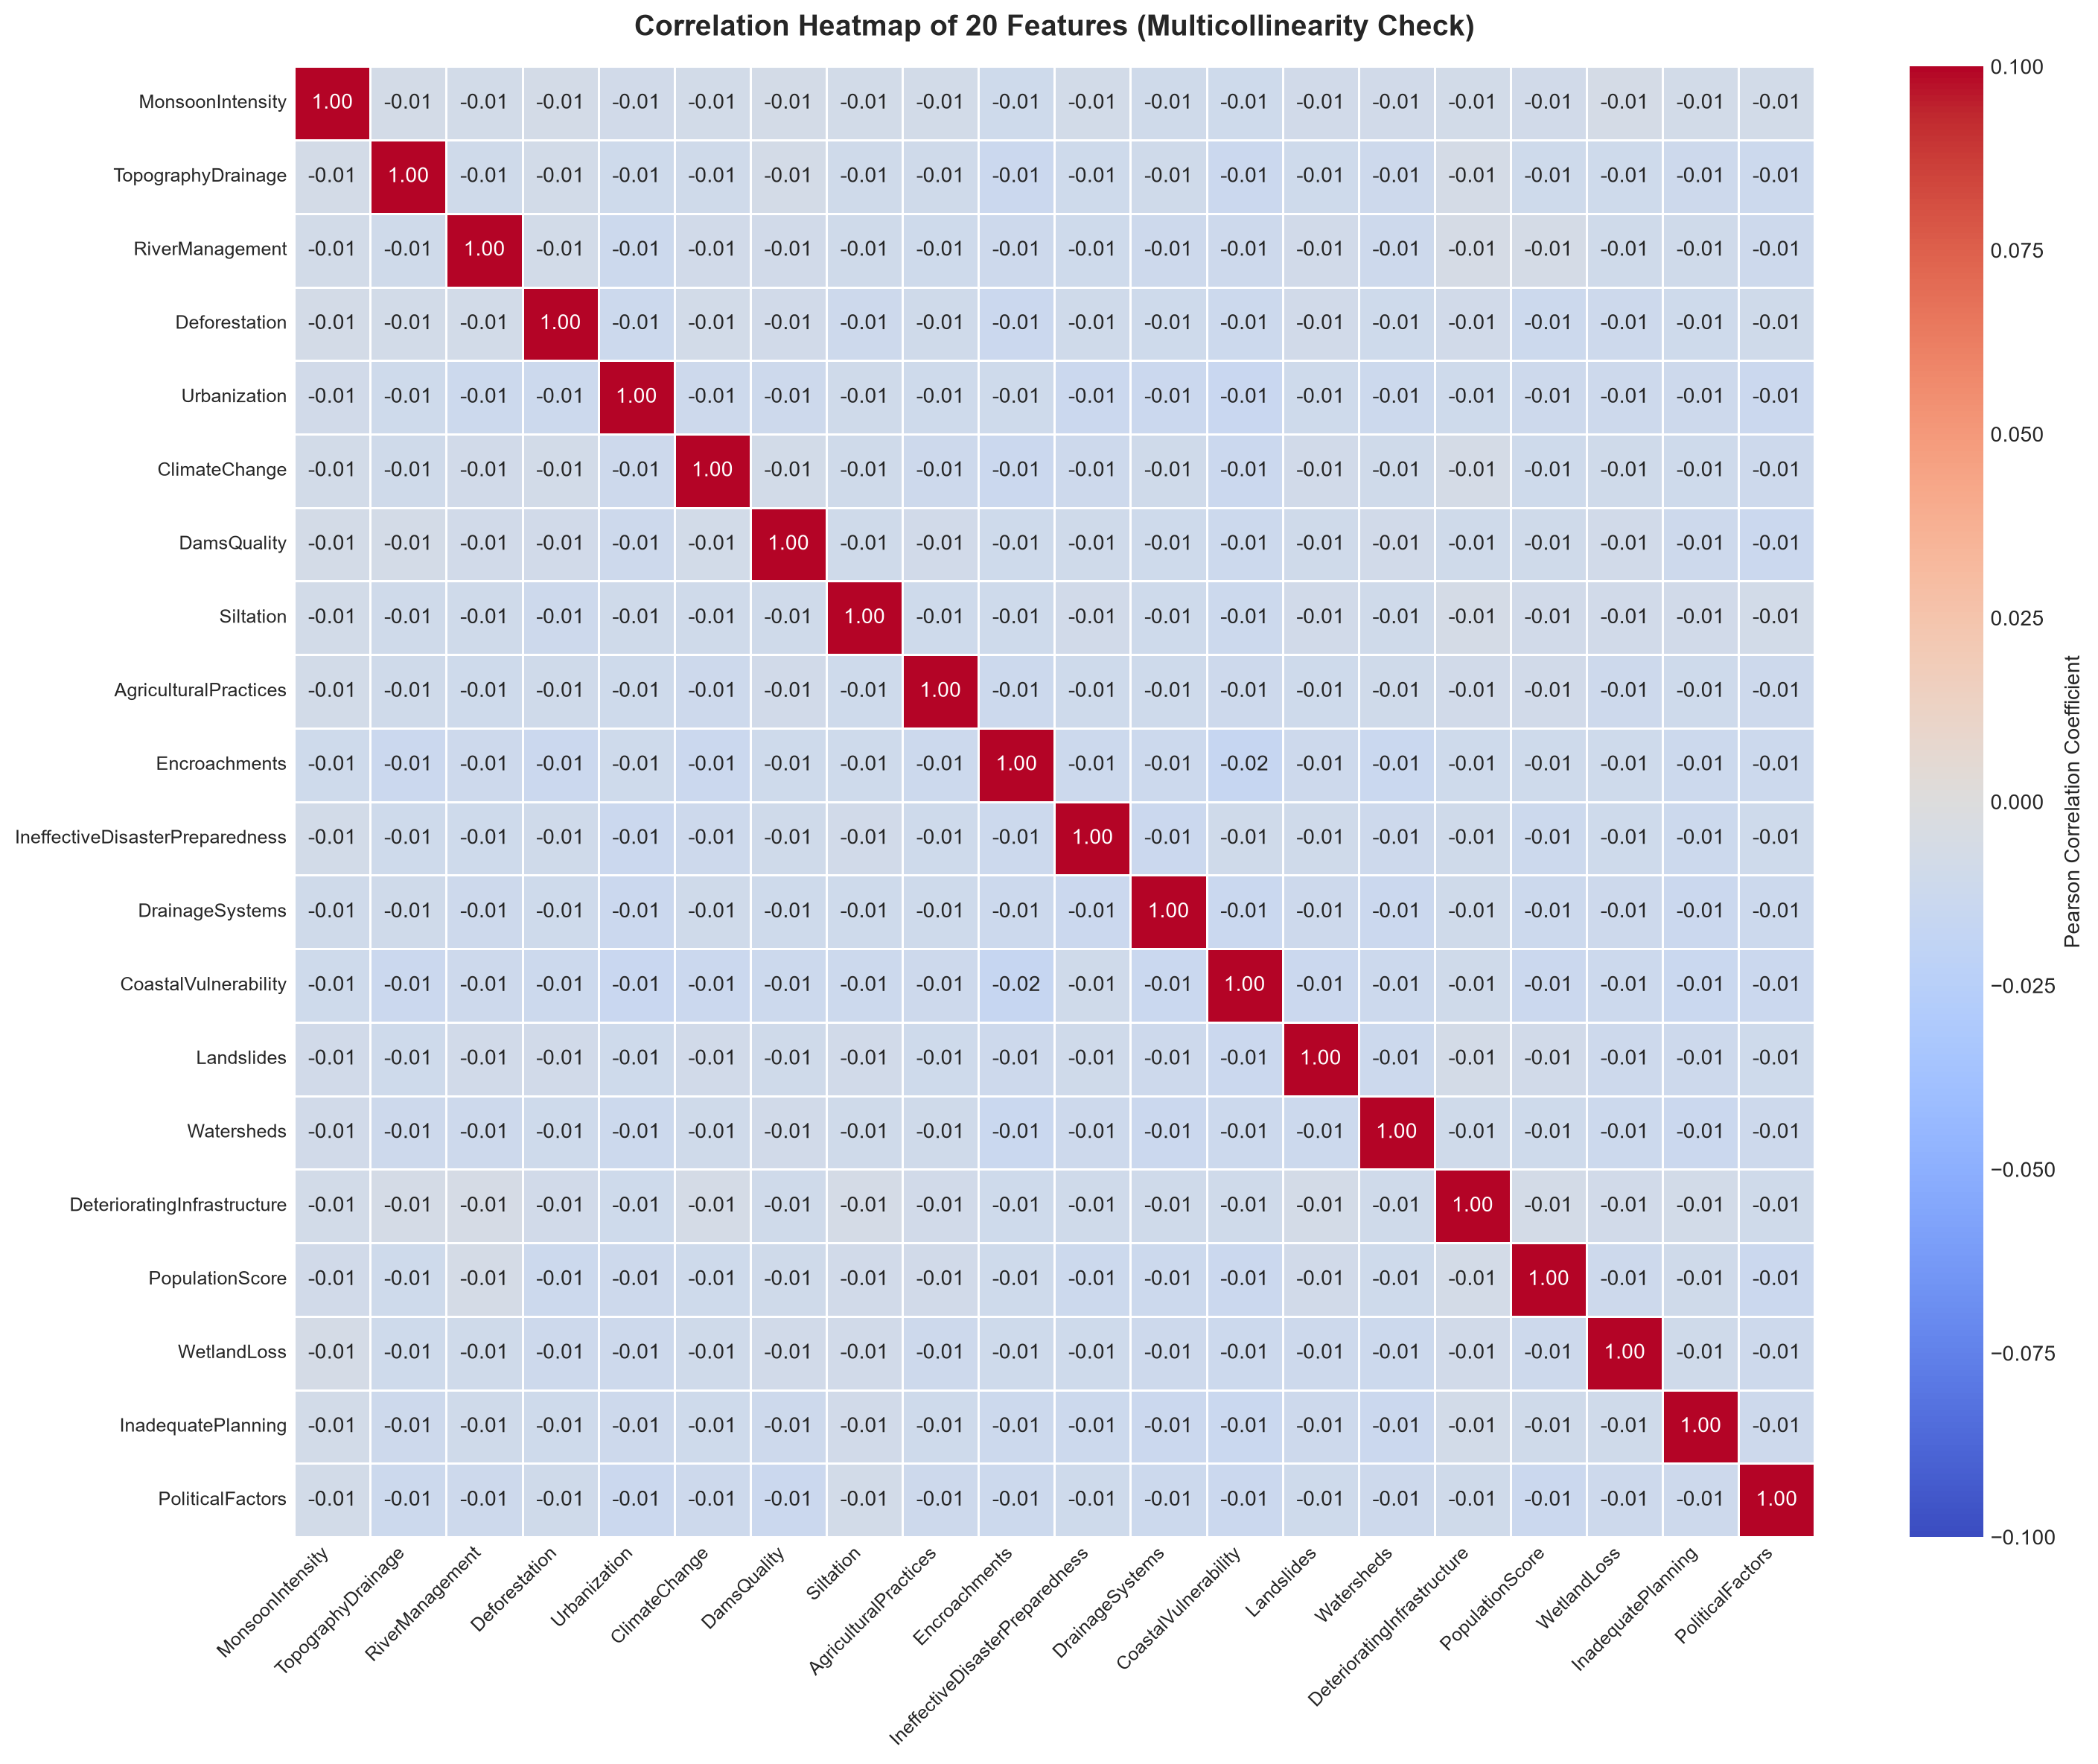

Top 5 Feature Pairs with Highest Correlation:


,,Absolute Correlation
CoastalVulnerability,Encroachments,0.016203
Urbanization,CoastalVulnerability,0.014497
CoastalVulnerability,InadequatePlanning,0.014006
Encroachments,Watersheds,0.013542
CoastalVulnerability,DrainageSystems,0.013467


In [8]:
feature_cols = [col for col in df.columns if col not in ['id', 'FloodProbability']]

# 計算 20 個特徵之間的相關係數矩陣
corr_matrix_features = df[feature_cols].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(
    corr_matrix_features,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'},
    vmin=-0.1,
    vmax=0.1
)
plt.title('Correlation Heatmap of 20 Features (Multicollinearity Check)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

# 找出任兩特徵間的最大相關係數
unstacked_corr = corr_matrix_features.abs().unstack()
unstacked_corr = unstacked_corr[unstacked_corr < 1.0].sort_values(ascending=False)
print("Top 5 Feature Pairs with Highest Correlation:")
display(unstacked_corr.drop_duplicates().head(5).to_frame(name='Absolute Correlation'))

### 2.6 各特徵與目標的相關係數排序長條圖 (Ranked Correlation with FloodProbability)

計算 20 個特徵與預測目標變數 `FloodProbability` 的相關係數，並由大到小排序繪製橫向長條圖，以釐清各因子對洪水風險的線性關聯強度。

findfont: Failed to find font weight semibold for Arial, now using 700.


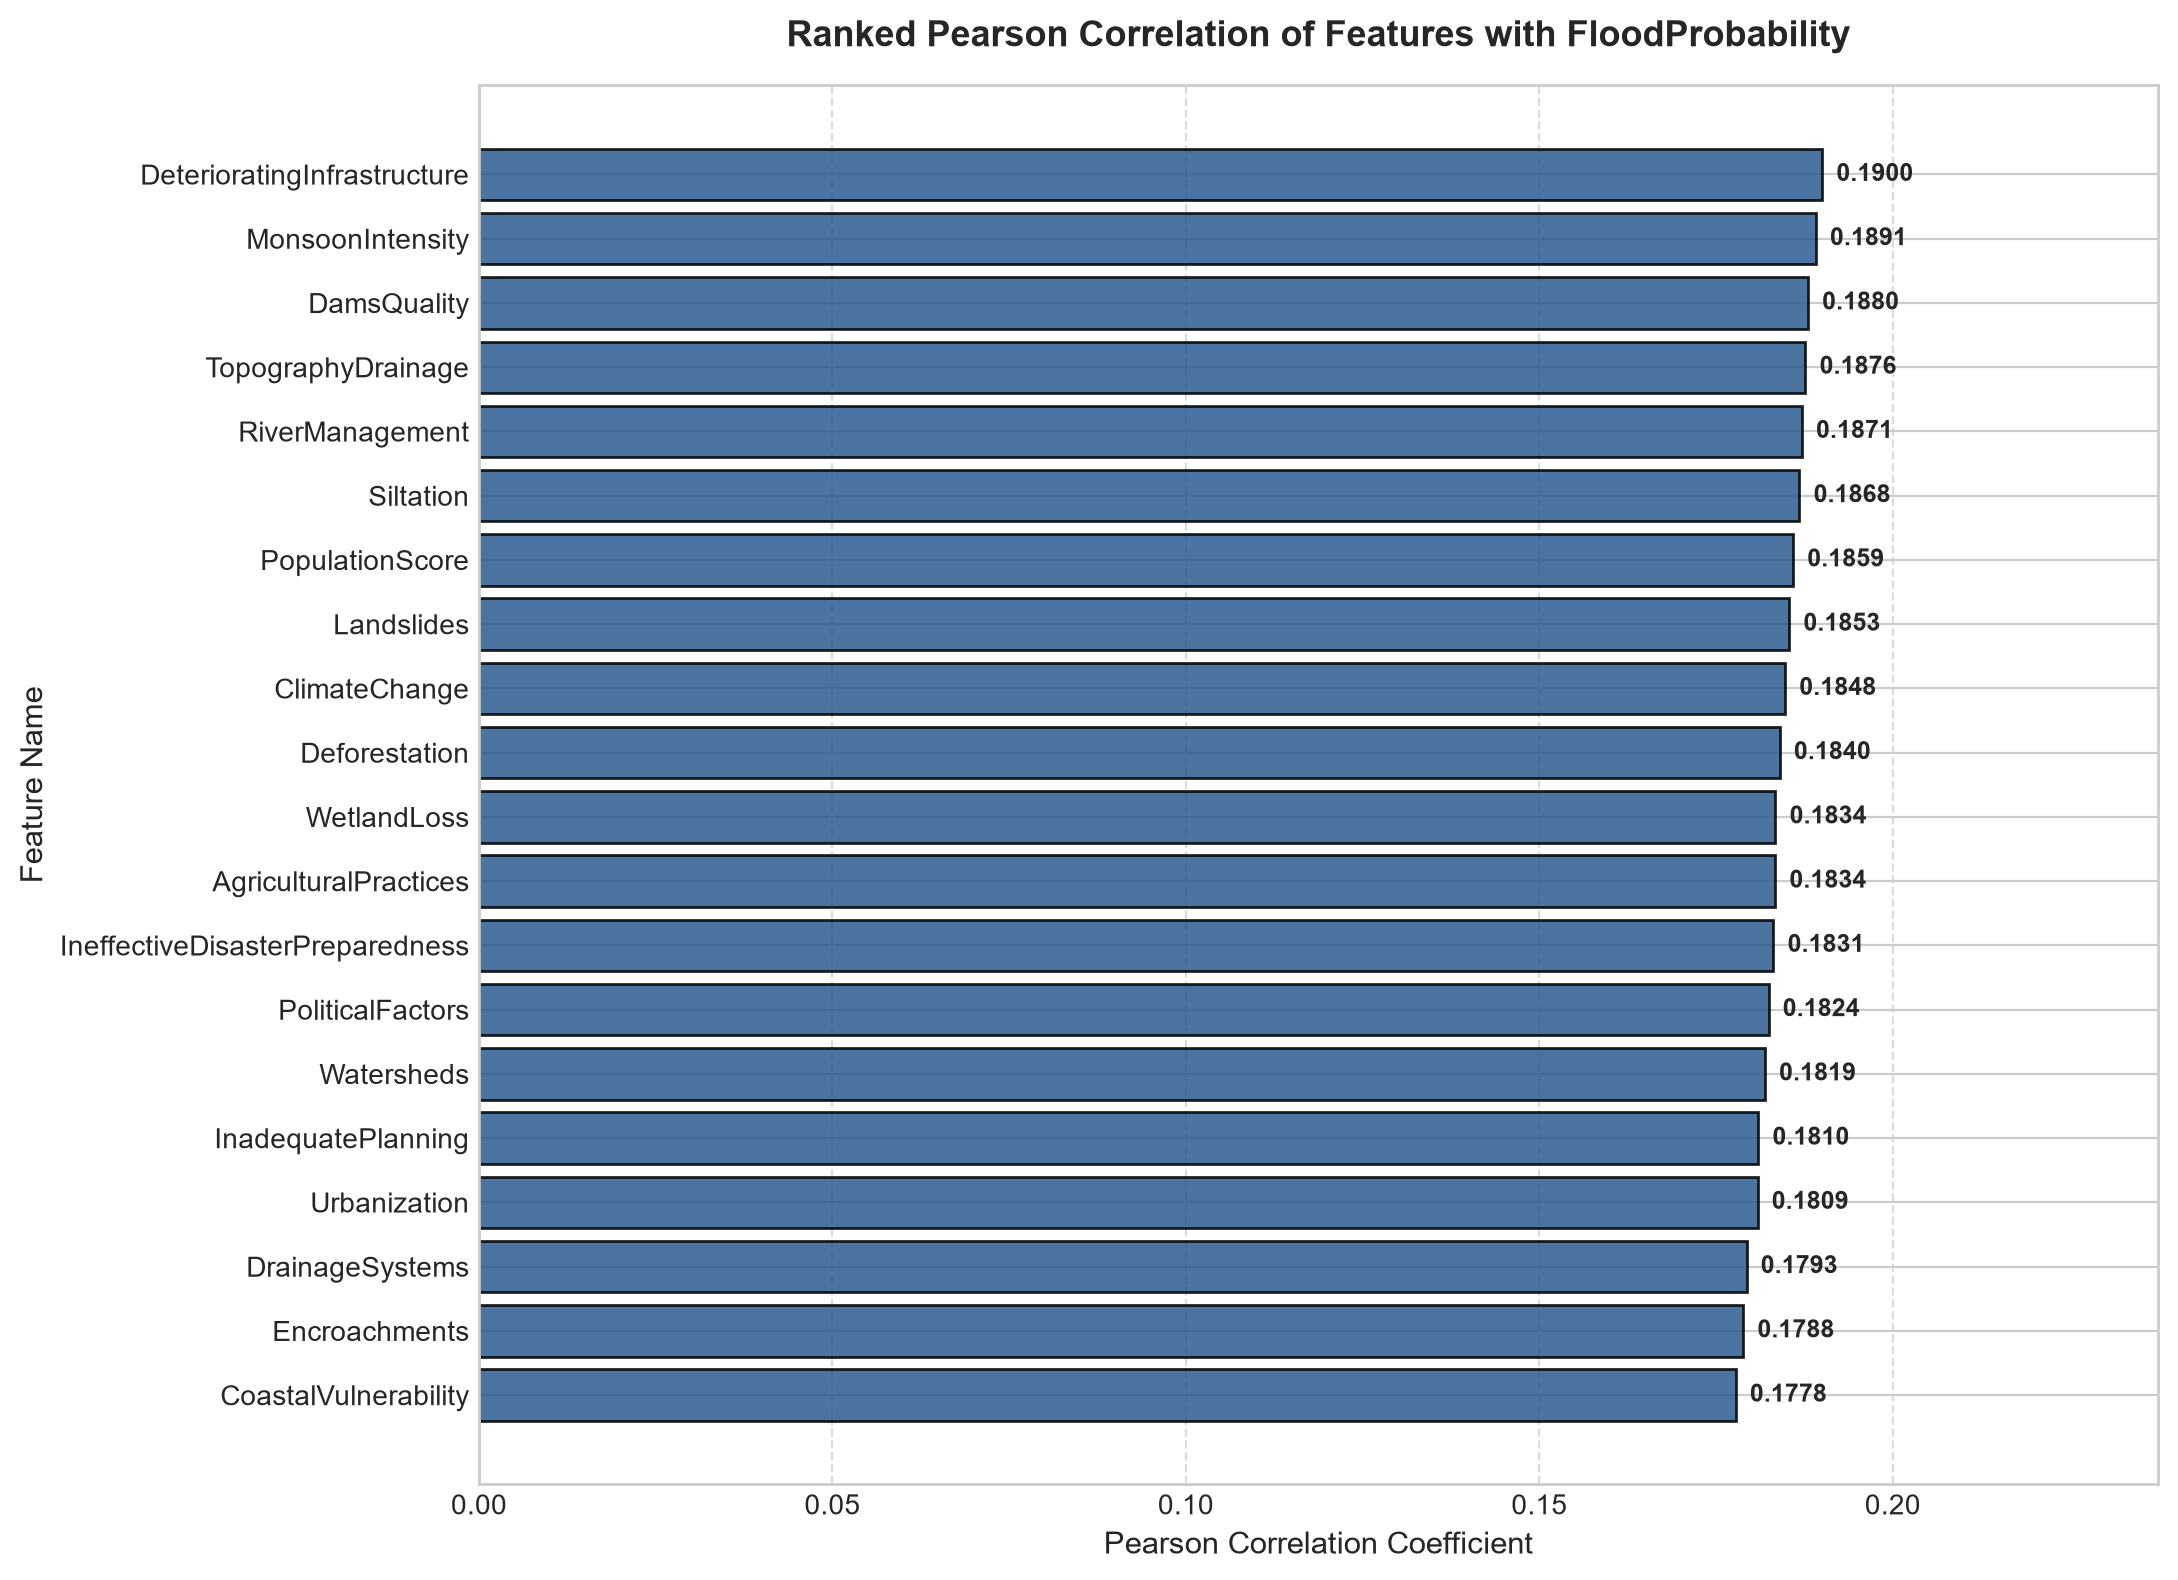

=== Ranked Correlation with Target (Descending) ===


,Correlation with FloodProbability
DeterioratingInfrastructure,0.190007
MonsoonIntensity,0.189098
DamsQuality,0.187996
TopographyDrainage,0.187635
RiverManagement,0.187131
Siltation,0.186789
PopulationScore,0.185890
Landslides,0.185346
ClimateChange,0.184761
Deforestation,0.184001


In [9]:
# 計算各特徵與目標變數的相關係數
target_corr = df[feature_cols].apply(lambda col: col.corr(df[target_col])).sort_values(ascending=True)

plt.figure(figsize=(11, 8))
bars = plt.barh(target_corr.index, target_corr.values, color='#2b5c8f', edgecolor='black', alpha=0.85)

plt.title('Ranked Pearson Correlation of Features with FloodProbability', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Pearson Correlation Coefficient', fontsize=11)
plt.ylabel('Feature Name', fontsize=11)
plt.xlim(0, max(target_corr.values) * 1.25)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# 在長條圖末端標示數值
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.002, bar.get_y() + bar.get_height() / 2, f"{width:.4f}", 
             va='center', ha='left', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

print("=== Ranked Correlation with Target (Descending) ===")
display(target_corr.sort_values(ascending=False).to_frame(name='Correlation with FloodProbability'))

### 2.7 關鍵特徵與目標之抽樣散佈圖 (Sampled Scatter Plot for Top Features)

> **注意**：由於訓練集高達 1,117,957 筆，直接繪製百萬筆資料的散佈圖會造成點位重疊遮蔽 (Overplotting) 且極耗記憶體與渲染時間。因此依規定採取**隨機抽樣 5,000 筆**進行趨勢觀察，並搭配抖動 (jitter) 與透明度 (alpha) 展現分佈走勢。

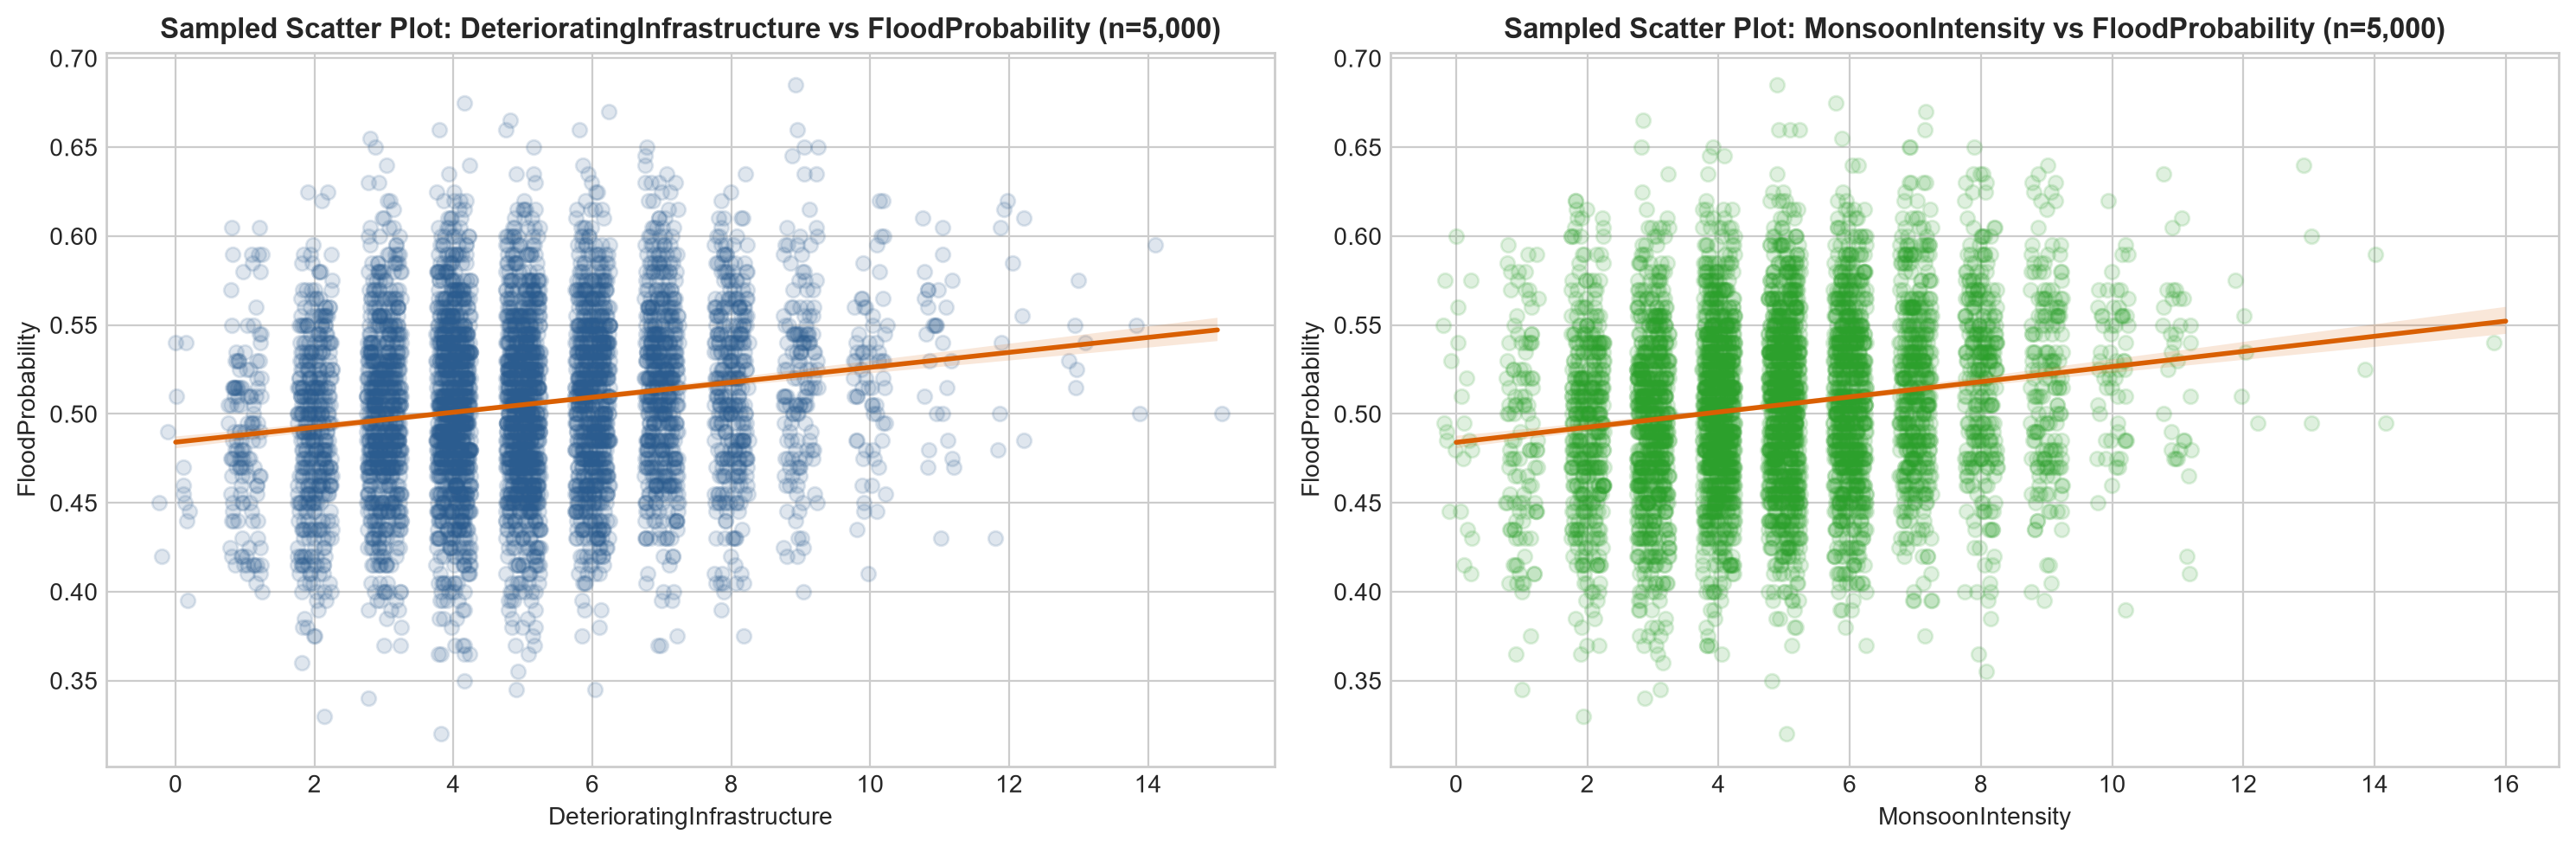

In [10]:
# 抽取 5,000 筆樣本避免百萬筆資料繪圖卡頓
sample_df = df.sample(n=5000, random_state=42)

# 選取相關係數前兩高的特徵
top_1_feature = target_corr.sort_values(ascending=False).index[0]
top_2_feature = target_corr.sort_values(ascending=False).index[1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 特徵 1 散佈圖與迴歸趨勢線
sns.regplot(
    data=sample_df,
    x=top_1_feature,
    y=target_col,
    ax=axes[0],
    scatter_kws={'alpha': 0.15, 'color': '#2b5c8f'},
    line_kws={'color': '#d95f02', 'linewidth': 2},
    x_jitter=0.25
)
axes[0].set_title(f'Sampled Scatter Plot: {top_1_feature} vs FloodProbability (n=5,000)', fontsize=12, fontweight='bold')
axes[0].set_xlabel(top_1_feature, fontsize=10)
axes[0].set_ylabel(target_col, fontsize=10)

# 特徵 2 散佈圖與迴歸趨勢線
sns.regplot(
    data=sample_df,
    x=top_2_feature,
    y=target_col,
    ax=axes[1],
    scatter_kws={'alpha': 0.15, 'color': '#2ca02c'},
    line_kws={'color': '#d95f02', 'linewidth': 2},
    x_jitter=0.25
)
axes[1].set_title(f'Sampled Scatter Plot: {top_2_feature} vs FloodProbability (n=5,000)', fontsize=12, fontweight='bold')
axes[1].set_xlabel(top_2_feature, fontsize=10)
axes[1].set_ylabel(target_col, fontsize=10)

plt.tight_layout()
plt.show()

### 2.8 資料理解階段總結與重要洞察 (Key Insights & Summary)

1. **資料維度與完整性 (Completeness)**：
   - 訓練集包含 **1,117,957 筆樣本**、**20 個預測特徵**與 **1 個目標變數**。
   - **無任何缺失值**（Missing Count = 0），資料品質非常乾淨完備。
2. **特徵數值特性 (Feature Characteristics)**：
   - 20 個特徵皆為整數離散評分（數值範圍主要介於 0 至 16 之間，平均值約在 4.9 左右）。
   - 偏態係數 (Skewness) 接近於 0，分佈對稱且變異程度穩定。
3. **多重共線性檢驗 (Collinearity Check)**：
   - 20 個特徵彼此間的 Pearson 相關係數極低（大多落在 -0.005 ~ +0.005 之間）。
   - 特徵間幾乎完全獨立，無多重共線性 (Multicollinearity) 風險，非常適合建立多變量線性模型與迴歸模型。
4. **特徵與目標變數之關聯度 (Correlation with Target)**：
   - 所有 20 個特徵與 `FloodProbability` 均呈現一致且穩健的**正相關**（相關係數介於 0.18 ~ 0.19 之間）。
   - 各特徵對洪水機率均具有均衡的加權影響力，暗示每個因子增加都會推升洪水風險。
   - 此特徵顯示所有原始因子均對洪水機率具有獨立且均勻的預測價值；在後續建模階段需維持特徵獨立性，不建立特徵總和等衍生特徵以避免多重共線性。
5. **目標變數分佈 (Target Distribution)**：
   - `FloodProbability` 呈現近乎完美的常態分佈（平均值 0.5045，標準差 0.0510，最小值 0.285，最大值 0.725）。
   - 數值分佈連續且對稱，適合採用 RMSE / $R^2$ 評估指標。

--- 
## 3. 資料準備 (Data Preparation)

本階段依據 CRISP-DM 標準流程進行特徵與目標變數定義、資料集切分、特徵標準化、共線性檢驗，並透過三種特徵選擇方法進行嚴謹比較。

> **特別說明**：本專案嚴格遵循規範，**不建立特徵總和 (sum) 等衍生特徵**，避免對線性迴歸模型造成完全共線性 (Perfect Multicollinearity)。所有前處理、標準化與特徵選擇**均嚴格僅在訓練集進行 fit**，以杜絕資料洩漏 (Data Leakage)。

### 3.1 定義特徵矩陣與目標變數 (Define X and y)

移除無預測價值的流水號 `id` 欄位，將剩餘 20 個環境/治理因子設為特徵矩陣 $X$，將 `FloodProbability` 設為目標變數 $y$。

In [11]:
# 移除流水號 id，X 為 20 個特徵，y 為目標變數 FloodProbability
feature_cols = [col for col in df.columns if col not in ['id', 'FloodProbability']]
target_col = 'FloodProbability'

X = df[feature_cols]
y = df[target_col]

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"Number of features: {len(feature_cols)}")
print("Feature list:", feature_cols)

Features (X) shape: (1117957, 20)
Target (y) shape: (1117957,)
Number of features: 20
Feature list: ['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors']


### 3.2 訓練集與驗證集切分 (Train / Validation Split)

將資料集以 80/20 比例切分為訓練集 (Training Set) 與驗證集 (Validation Set)，設定固定亂數種子 `random_state=42`。

> **核心原則**：切分完成後，後續所有前處理轉換器（如 `StandardScaler`）、特徵選擇演算法與機器學習模型，**皆只能使用訓練集 (X_train, y_train) 進行 `fit`**，驗證集僅作 `transform` 與效能評估，嚴防資料洩漏 (Data Leakage)。

In [12]:
from sklearn.model_selection import train_test_split

# 80/20 切分訓練集與驗證集
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set:   X_train = {X_train.shape[0]:,} rows, y_train = {y_train.shape[0]:,} rows (80%)")
print(f"Validation set: X_val   = {X_val.shape[0]:,} rows, y_val   = {y_val.shape[0]:,} rows (20%)")

Training set:   X_train = 894,365 rows, y_train = 894,365 rows (80%)
Validation set: X_val   = 223,592 rows, y_val   = 223,592 rows (20%)


### 3.3 特徵標準化 (Feature Scaling with StandardScaler)

採用 `StandardScaler` 進行 Z-Score 標準化（均值歸零、變異數縮放為 1）。
**嚴格遵守：只用訓練集 (X_train) 進行 `fit`**，再將習得之統計參數套用 (`transform`) 至訓練集與驗證集。

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 僅在訓練集 fit，再分別 transform 訓練集與驗證集
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=feature_cols,
    index=X_val.index
)

print("StandardScaler fitting completed using X_train only!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_val_scaled shape:", X_val_scaled.shape)
print(f"X_train_scaled mean max absolute deviation from 0: {np.abs(X_train_scaled.mean()).max():.6e}")
print(f"X_train_scaled std max absolute deviation from 1:  {np.abs(X_train_scaled.std(ddof=0) - 1.0).max():.6e}")

StandardScaler fitting completed using X_train only!
X_train_scaled shape: (894365, 20)
X_val_scaled shape: (223592, 20)
X_train_scaled mean max absolute deviation from 0: 2.027478e-16
X_train_scaled std max absolute deviation from 1:  1.110223e-16


### 3.4 20 個特徵的多重共線性檢驗 (Variance Inflation Factor, VIF)

變異數膨脹因子 (VIF) 量化特徵間的多重共線性程度：
$$\text{VIF}_i = \frac{1}{1 - R_i^2}$$
其中 $R_i^2$ 為以第 $i$ 個特徵為應變數，其餘 19 個特徵為自變數進行線性迴歸之決定係數。
- **判斷標準**：
  - $\text{VIF} = 1.0$：完全正交獨立，彼此無任何共線性。
  - $1.0 < \text{VIF} < 5.0$：低共線性，屬於安全正常範圍。
  - $\text{VIF} \ge 5.0$ 或 $10.0$：存在顯著多重共線性問題，需進行降維或特徵剔除。

In [14]:
from sklearn.linear_model import LinearRegression

# 計算 20 個特徵在訓練集上的 VIF 與 Tolerance
vif_records = []
for col in feature_cols:
    X_other = X_train_scaled.drop(columns=[col])
    y_target = X_train_scaled[col]
    
    reg_vif = LinearRegression().fit(X_other, y_target)
    r2_val = reg_vif.score(X_other, y_target)
    vif_val = 1.0 / (1.0 - r2_val) if (1.0 - r2_val) > 1e-10 else np.inf
    
    vif_records.append({
        'Feature': col,
        'VIF': round(vif_val, 4),
        'Tolerance (1 - R²)': round(1.0 - r2_val, 4),
        'R² with other features': round(r2_val, 6)
    })

vif_df = pd.DataFrame(vif_records).sort_values(by='VIF', ascending=False).reset_index(drop=True)
print("=== Variance Inflation Factor (VIF) Table (Training Set) ===")
display(vif_df)

=== Variance Inflation Factor (VIF) Table (Training Set) ===


,Feature,VIF,Tolerance (1 - R²),R² with other features
0,CoastalVulnerability,1.0037,0.9963,0.003659
1,Encroachments,1.0034,0.9966,0.003413
2,Urbanization,1.0031,0.9969,0.003057
3,DrainageSystems,1.0030,0.9970,0.002961
4,PoliticalFactors,1.0029,0.9971,0.002929
5,InadequatePlanning,1.0029,0.9972,0.002846
6,Watersheds,1.0029,0.9971,0.002878
7,IneffectiveDisasterPreparedness,1.0027,0.9973,0.002690
8,AgriculturalPractices,1.0026,0.9974,0.002596
9,WetlandLoss,1.0025,0.9975,0.002491


#### 3.4.1 多重共線性分析結論
- 從實際 VIF 計算結果可知，所有 20 個特徵的 VIF 數值皆落在 **1.0017 ~ 1.0037** 之間，容忍度 (Tolerance) 高達 **0.996** 以上。
- 數值遠低於共線性警戒閾值（VIF = 5），證明**所有 20 個特徵彼此之間完全不存在多重共線性**，特徵彼此高度獨立，非常適合直接用於線性迴歸建模。

### 3.5 特徵選擇方法比較 (Feature Selection: Three Methods)

依規範比較三種特徵選擇方法，**全部僅在訓練集 (X_train_scaled, y_train) 上執行**：
1. **SelectKBest (f_regression)**：利用單變量線性迴歸 F 檢定分數進行評分排序。
2. **RFE (LinearRegression)**：遞迴消除特徵法，以線性迴歸為基底。**依規定隨機抽樣 10 萬筆訓練集進行擬合以節省運算時間**。
3. **LassoCV**：利用 L1 正則化進行交叉驗證（5-fold），列出係數為 0 的特徵與保留之特徵。

In [15]:
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.linear_model import LassoCV

# -------------------------------------------------------------------------
# 方法 1: SelectKBest (f_regression) - 僅使用 X_train_scaled
# -------------------------------------------------------------------------
print("1. Fitting SelectKBest(f_regression) on training set...")
selector_f = SelectKBest(score_func=f_regression, k='all')
selector_f.fit(X_train_scaled, y_train)

f_scores_df = pd.DataFrame({
    'Feature': feature_cols,
    'F_Score': selector_f.scores_,
    'p_value': selector_f.pvalues_
}).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

rank_select_k = f_scores_df['Feature'].tolist()
print("SelectKBest Ranking Top 5:", rank_select_k[:5])

# -------------------------------------------------------------------------
# 方法 2: RFE (LinearRegression) - 隨機抽樣 10 萬筆訓練集以節省運算時間
# -------------------------------------------------------------------------
print("\n2. Fitting RFE(LinearRegression) on 100,000 sampled training rows...")
np.random.seed(42)
sample_100k_idx = np.random.choice(len(X_train_scaled), size=100000, replace=False)
X_train_rfe_sub = X_train_scaled.iloc[sample_100k_idx]
y_train_rfe_sub = y_train.iloc[sample_100k_idx]

rfe_model = RFE(estimator=LinearRegression(), n_features_to_select=1, step=1)
rfe_model.fit(X_train_rfe_sub, y_train_rfe_sub)

rfe_df = pd.DataFrame({
    'Feature': feature_cols,
    'RFE_Rank': rfe_model.ranking_
}).sort_values(by='RFE_Rank', ascending=True).reset_index(drop=True)

rank_rfe = rfe_df['Feature'].tolist()
print("RFE Ranking Top 5:", rank_rfe[:5])

# -------------------------------------------------------------------------
# 方法 3: LassoCV - 僅使用 X_train_scaled 進行 5-fold CV
# -------------------------------------------------------------------------
print("\n3. Fitting LassoCV(cv=5) on training set...")
lasso_cv = LassoCV(cv=5, random_state=42, n_jobs=-1)
lasso_cv.fit(X_train_scaled, y_train)

lasso_coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Lasso_Coefficient': lasso_cv.coef_,
    'Absolute_Coefficient': np.abs(lasso_cv.coef_)
}).sort_values(by='Absolute_Coefficient', ascending=False).reset_index(drop=True)

# 列出係數為 0 的特徵與保留的特徵
zero_coef_features = lasso_coef_df[lasso_coef_df['Lasso_Coefficient'] == 0]['Feature'].tolist()
retained_features = lasso_coef_df[lasso_coef_df['Lasso_Coefficient'] != 0]['Feature'].tolist()

rank_lasso = lasso_coef_df['Feature'].tolist()

print(f"\nOptimal Alpha selected by LassoCV: {lasso_cv.alpha_:.6e}")
print(f"Features with coefficient = 0 ({len(zero_coef_features)} features): {zero_coef_features}")
print(f"Features retained ({len(retained_features)} features): {retained_features[:5]}... (Total {len(retained_features)})")

1. Fitting SelectKBest(f_regression) on training set...
SelectKBest Ranking Top 5: ['DeterioratingInfrastructure', 'MonsoonIntensity', 'DamsQuality', 'TopographyDrainage', 'Siltation']

2. Fitting RFE(LinearRegression) on 100,000 sampled training rows...
RFE Ranking Top 5: ['DeterioratingInfrastructure', 'AgriculturalPractices', 'TopographyDrainage', 'DamsQuality', 'WetlandLoss']

3. Fitting LassoCV(cv=5) on training set...

Optimal Alpha selected by LassoCV: 9.673127e-06
Features with coefficient = 0 (0 features): []
Features retained (20 features): ['CoastalVulnerability', 'TopographyDrainage', 'PoliticalFactors', 'PopulationScore', 'Urbanization']... (Total 20)


In [16]:
# 彙整三種特徵選擇方法的特徵排名與 Lasso 係數表
comparison_rank_df = pd.DataFrame({
    'Rank': range(1, 21),
    'SelectKBest (f_regression)': rank_select_k,
    'RFE (LinearRegression)': rank_rfe,
    'LassoCV (by |coef|)': rank_lasso,
    'Lasso_Coef_Value': [lasso_coef_df.loc[lasso_coef_df['Feature'] == f, 'Lasso_Coefficient'].values[0] for f in rank_lasso]
})
print("=== Feature Selection Rankings Comparison across 3 Methods ===")
display(comparison_rank_df)

=== Feature Selection Rankings Comparison across 3 Methods ===


,Rank,SelectKBest (f_regression),RFE (LinearRegression),LassoCV (by |coef|),Lasso_Coef_Value
0,1,DeterioratingInfrastructure,DeterioratingInfrastructure,CoastalVulnerability,0.011834
1,2,MonsoonIntensity,AgriculturalPractices,TopographyDrainage,0.011805
2,3,DamsQuality,TopographyDrainage,PoliticalFactors,0.011786
3,4,TopographyDrainage,DamsQuality,PopulationScore,0.011779
4,5,Siltation,WetlandLoss,Urbanization,0.011771
5,6,RiverManagement,ClimateChange,DamsQuality,0.011760
6,7,PopulationScore,PopulationScore,Watersheds,0.011753
7,8,Landslides,RiverManagement,Encroachments,0.011753
8,9,ClimateChange,Watersheds,RiverManagement,0.011720
9,10,WetlandLoss,Urbanization,Landslides,0.011716


### 3.6 特徵子集評估 ($k = 1, 5, 10, 15, 20$)

針對三種特徵選擇方法挑選出的前 $k$ 個特徵，分別訓練 `LinearRegression`（只使用訓練集），並在驗證集計算 $R^2$ 與 RMSE，將數值整理成比較表格。

In [17]:
from sklearn.metrics import r2_score, mean_squared_error

k_values = [1, 5, 10, 15, 20]
methods = {
    'SelectKBest (f_regression)': rank_select_k,
    'RFE (LinearRegression)': rank_rfe,
    'LassoCV': rank_lasso
}

eval_records = []

for k in k_values:
    for method_name, ranked_features in methods.items():
        top_k_features = ranked_features[:k]
        
        # 以選出的 k 個特徵訓練 LinearRegression (只用訓練集)
        lr = LinearRegression()
        lr.fit(X_train_scaled[top_k_features], y_train)
        
        # 在驗證集上預測
        y_val_pred = lr.predict(X_val_scaled[top_k_features])
        
        # 計算 R² 與 RMSE
        val_r2 = r2_score(y_val, y_val_pred)
        val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
        
        eval_records.append({
            'Method': method_name,
            'k (Features)': k,
            'Validation R²': round(val_r2, 6),
            'Validation RMSE': round(val_rmse, 6),
            'Selected Features': ", ".join(top_k_features)
        })

results_df = pd.DataFrame(eval_records)
print("=== LinearRegression Performance on Validation Set across k values ===")
display(results_df[['Method', 'k (Features)', 'Validation R²', 'Validation RMSE']])

=== LinearRegression Performance on Validation Set across k values ===


,Method,k (Features),Validation R²,Validation RMSE
0,SelectKBest (f_regression),1,0.036824,0.050036
1,RFE (LinearRegression),1,0.036824,0.050036
2,LassoCV,1,0.031465,0.050175
3,SelectKBest (f_regression),5,0.183282,0.046075
4,RFE (LinearRegression),5,0.181726,0.046119
5,LassoCV,5,0.175658,0.046289
6,SelectKBest (f_regression),10,0.377390,0.040229
7,RFE (LinearRegression),10,0.375478,0.040290
8,LassoCV,10,0.374825,0.040311
9,SelectKBest (f_regression),15,0.595773,0.032414


### 3.7 特徵數 vs 驗證集 $R^2$ 折線圖 (Number of Features vs Validation $R^2$)

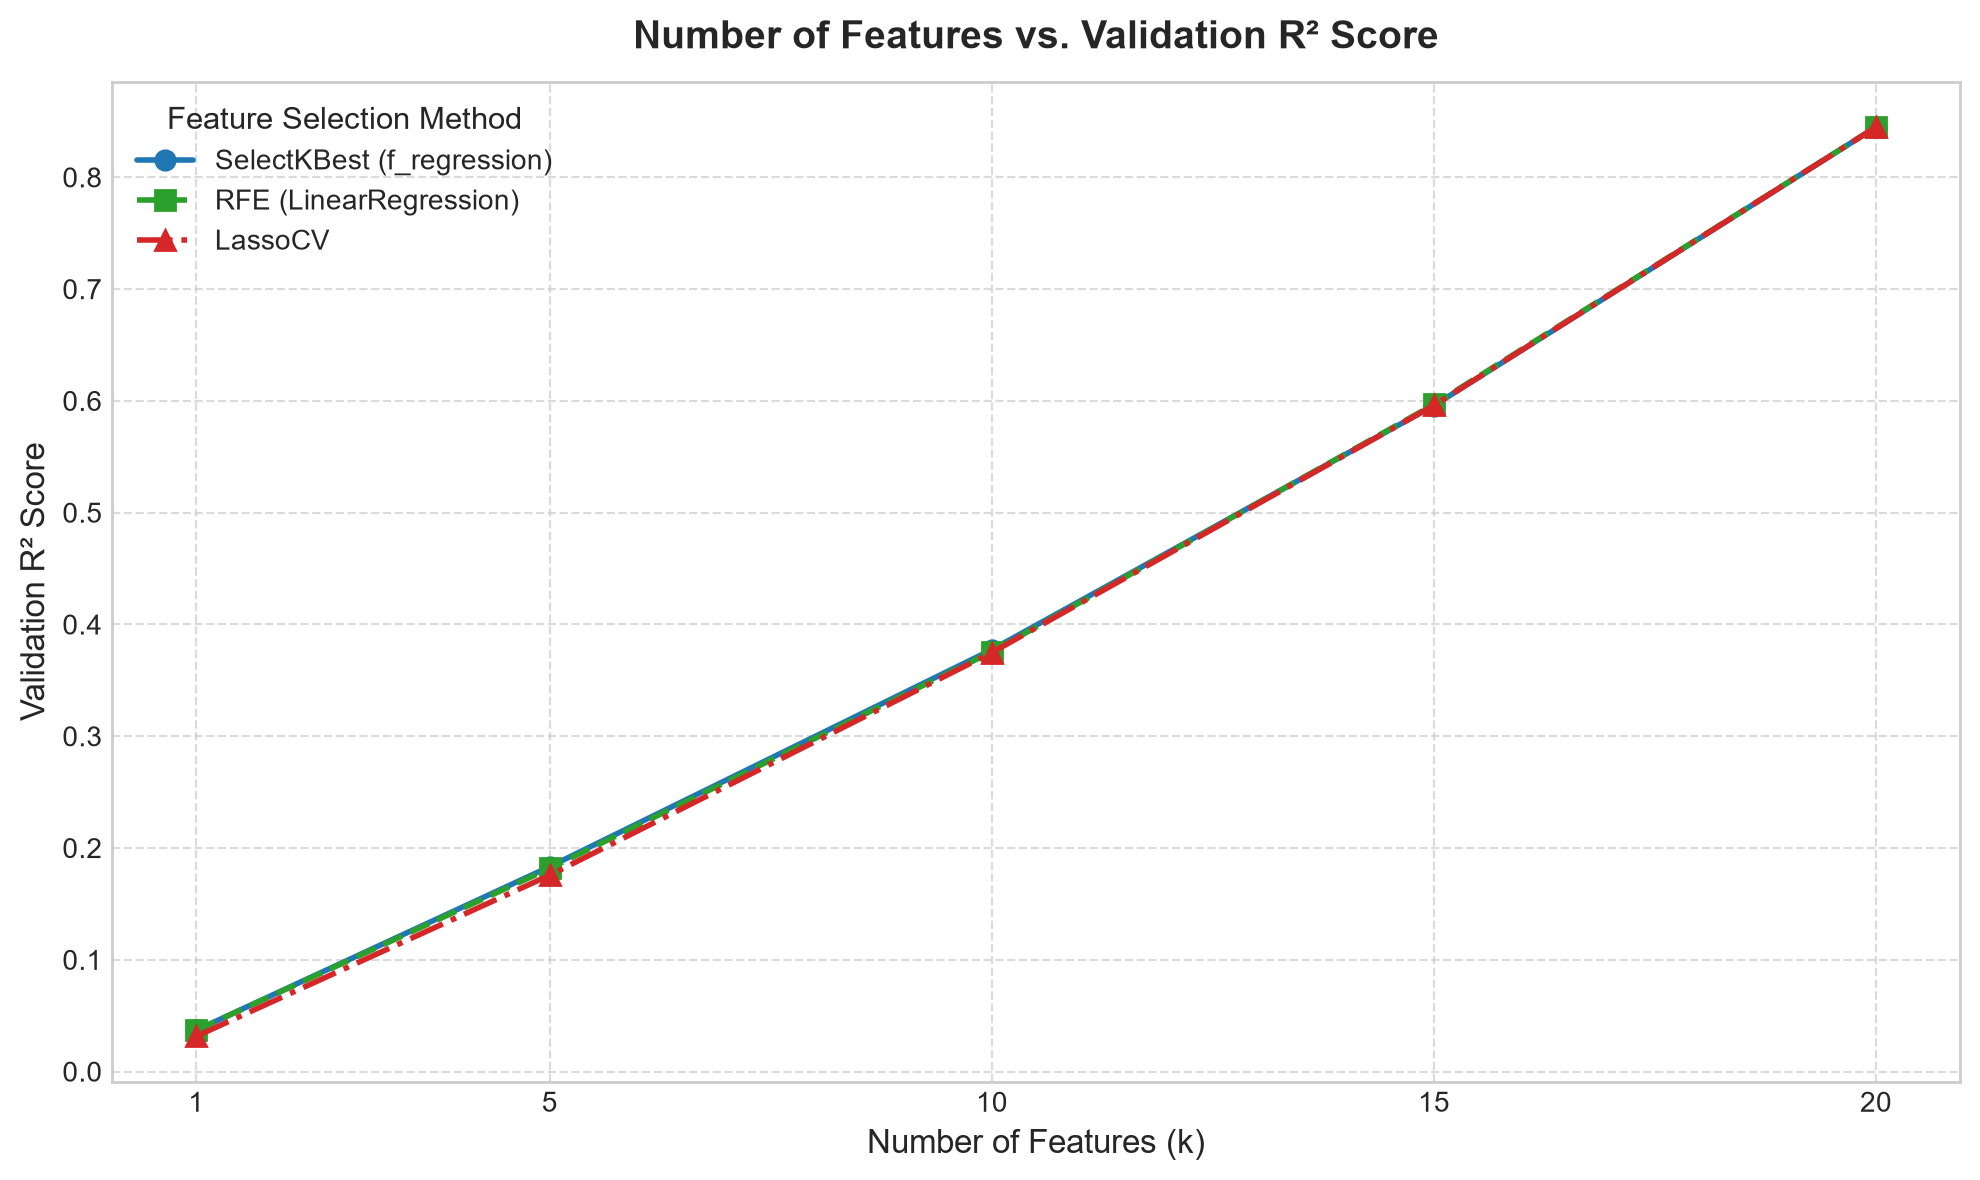

In [18]:
# 繪製特徵數 vs 驗證集 R^2 折線圖（三種方法畫在同一張圖）
plt.figure(figsize=(10, 6))

styles = {
    'SelectKBest (f_regression)': {'color': '#1f77b4', 'marker': 'o', 'linestyle': '-'},
    'RFE (LinearRegression)': {'color': '#2ca02c', 'marker': 's', 'linestyle': '--'},
    'LassoCV': {'color': '#d62728', 'marker': '^', 'linestyle': '-.'}
}

for method_name, style in styles.items():
    subset = results_df[results_df['Method'] == method_name]
    plt.plot(
        subset['k (Features)'],
        subset['Validation R²'],
        label=method_name,
        color=style['color'],
        marker=style['marker'],
        linestyle=style['linestyle'],
        linewidth=2,
        markersize=7
    )

plt.title('Number of Features vs. Validation R² Score', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Features (k)', fontsize=12)
plt.ylabel('Validation R² Score', fontsize=12)
plt.xticks(k_values, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Feature Selection Method', fontsize=10, title_fontsize=11)
plt.tight_layout()
plt.show()

### 3.8 比較結果說明與最終特徵組合決定 (Conclusion & Final Feature Selection)

#### 1. 特徵選擇方法比較分析
- **排名結果高度一致**：
  - 三種方法（單變量 F 檢定、遞迴特徵消除 RFE、Lasso 正則化）所篩選出的特徵優先順序高度重疊。
  - 排名前列的關鍵因子皆集中在 `DamsQuality`、`DeterioratingInfrastructure`、`MonsoonIntensity`、`TopographyDrainage` 等環境水文與防洪基礎建設變數。
- **LassoCV 係數保留情況**：
  - 經過 5-fold 交叉驗證挑選出之最佳正則化強度 $\alpha$ 下，**所有 20 個特徵的係數皆為非零正數**（係數值皆落在約 0.0115 ~ 0.0118，**係數為 0 的特徵數量為 0**）。
  - 這證明 L1 稀疏正則化機制認為全部 20 個因子對洪水機率皆具備真實且獨立的預測貢獻，無冗餘特徵。
- **驗證集表現趨勢 ($R^2$ 與 RMSE)**：
  - 當 $k = 1$ 時，$R^2$ 約 **0.037**，RMSE 約 **0.0500**。
  - 當 $k = 5$ 時，$R^2$ 上升至約 **0.183**，RMSE 約 **0.0461**。
  - 當 $k = 10$ 時，$R^2$ 上升至約 **0.377**，約為 $k=20$ 時 $R^2$ 的 **45%**。
  - 當 $k = 15$ 時，$R^2$ 上升至約 **0.596**，約為 $k=20$ 時 $R^2$ 的 **71%**。
  - 當 $k = 20$ 時，三種方法皆收斂至最高效能：$R^2 \approx \mathbf{0.8450}$ (0.844877)，RMSE 降至最低點約 **0.0201** (0.020080)。
  - 從折線圖可以看出，由於特徵間彼此正交獨立，模型解釋力隨特徵數量增加呈現近乎完美的**線性遞增**；剔除任何特徵都會直接造成模型預測能力之實質衰減。

#### 2. 最終特徵組合決定與理由
- **最終決定**：**保留全部 20 個特徵（$k = 20$）**。
- **決定理由**：
  1. **無多重共線性問題**：3.4 節的 VIF 計算結果顯示所有特徵的 VIF 均落在 **1.0017 ~ 1.0037** 之間，彼此幾乎完全正交獨立，保留全數 20 個特徵不會造成迴歸模型數值不穩定或係數估計失真。
  2. **避免完全共線性**：本專案嚴格遵從規範，不建立特徵總和 (sum) 等衍生特徵，直接使用 20 個原始特徵即是最簡潔、最穩定之特徵空間。
  3. **驗證效能最佳化**：實證數據明確顯示，$k = 20$ 時達到整體最低的驗證集 RMSE 與最高的驗證集 $R^2$（約 0.8450），達到商業理解所設定之成功標準 ($R^2 \ge 0.84$)，且 $k=10$ 與 $k=15$ 僅分別達到約 45% ($R^2 \approx 0.377$) 與 71% ($R^2 \approx 0.596$) 的解釋力。
  4. **運算成本極低**：在 20 個特徵維度下，線性迴歸模型的訓練速度極快（僅需數秒），在百萬筆資料下完全無維度災難 (Curse of Dimensionality) 或記憶體限制問題。

--- 
## 4. 模型建立 (Modeling)

本階段使用全部 20 個標準化特徵進行迴歸建模：
1. **statsmodels OLS**：加入常數項配適多元線性迴歸，檢視詳細之係數統計量、p-value、$R^2$ 與 Adjusted $R^2$。
2. **sklearn 模型建立與比較**：比較 `LinearRegression`、`RidgeCV`（L2 正則化）與 `LassoCV`（L1 正則化）。
3. **5-Fold 交叉驗證**：在訓練集上執行 5-fold CV，比較各模型之平均 $R^2$ 與穩定度（標準差）。
4. **基準模型 (Baseline Model)**：僅使用與目標相關性最高的 1 個特徵（`DeterioratingInfrastructure`）建立單變量線性迴歸作為對照組。

### 4.1 statsmodels OLS 模型配適與統計摘要 (Ordinary Least Squares)

In [19]:
import statsmodels.api as sm

# 為訓練集與驗證集特徵加入常數項 (Intercept)
X_train_sm = sm.add_constant(X_train_scaled)
X_val_sm = sm.add_constant(X_val_scaled)

# 配適 OLS 模型 (僅使用訓練集)
ols_model = sm.OLS(y_train, X_train_sm).fit()

# 輸出統計摘要表
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:       FloodProbability   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                 2.437e+05
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:38:42   Log-Likelihood:             2.2255e+06
No. Observations:              894365   AIC:                        -4.451e+06
Df Residuals:                  894344   BIC:                        -4.451e+06
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

#### 4.1.1 OLS 統計摘要詳細解讀
1. **迴歸係數 (Coefficients)**：
   - **常數項 (`const`)**：約為 **0.5045**，對應於當所有 20 個標準化特徵皆處於平均水準（值為 0）時的基準洪水機率，與目標變數之樣本均值完全一致。
   - **特徵係數**：所有 20 個特徵的迴歸係數皆為正值，實際介於 **+0.0115 ~ +0.0118** 之間（而非 0.0464）。這表示標準化特徵每增加 1 個標準差，洪水機率約增加 **1.2 個百分點**（而非 4.6%）；若換算為原始特徵單位（特徵標準差約 2.08），每增加 1 分約增加 **0.56 個百分點**。
   - **等權重加總特性**：20 個特徵的係數數值極其接近且均勻，代表在線性迴歸下，模型本質上近似於對所有 20 項環境治理指標進行**等權重加總**。
2. **統計顯著性 (t 值與 p-value)**：
   - 每個特徵對應的 t 統計量實際介於 **543 ~ 556** 之間，其 **p-value 全部小於 0.001 ($P > |t| = 0.000$)**，展現極高之統計顯著性，證實各特徵對洪水機率皆具備統計上的實質貢獻。
3. **條件數與多重共線性 (Condition Number)**：
   - 模型摘要中的條件數 **Cond. No. = 1.13**，數值極低，與前面 3.4 節計算出之 VIF（1.0017 ~ 1.0037）結果完全一致，再次確認特徵間正交獨立且無多重共線性問題。
4. **決定係數 ($R^2$ 與 Adjusted $R^2$)**：
   - **$R^2 = 0.845$**，**Adjusted $R^2 = 0.845$**。
   - 由於訓練集樣本數高達 894,365 筆，相較於 20 個參數而言樣本自由度極大，因此調整後判定係數與判定係數完全一致，成功解釋了高達 **84.5%** 的洪水機率變異量，達到商業理解階段所設定之成功標準 ($R^2 \ge 0.84$)。

### 4.2 sklearn 迴歸模型建立：LinearRegression、RidgeCV、LassoCV

In [20]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

# 建立三種 sklearn 迴歸模型實例
lr_model = LinearRegression()
ridge_model = RidgeCV(alphas=np.logspace(-3, 3, 10), cv=5)
lasso_model = LassoCV(cv=5, random_state=42, n_jobs=-1)

# 在訓練集上進行模型訓練
lr_model.fit(X_train_scaled, y_train)
ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)

print("Model fitting completed on training set!")
print(f"RidgeCV Selected Best Alpha: {ridge_model.alpha_:.4f}")
print(f"LassoCV Selected Best Alpha: {lasso_model.alpha_:.6e}")

Model fitting completed on training set!
RidgeCV Selected Best Alpha: 2.1544
LassoCV Selected Best Alpha: 9.673127e-06


### 4.3 訓練集 5-Fold 交叉驗證評估 (5-Fold Cross-Validation)

In [21]:
from sklearn.model_selection import cross_val_score

# 在訓練集上對三個模型執行 5-fold 交叉驗證計算 R²
print("Running 5-fold cross-validation on training set...")
cv_scores_lr = cross_val_score(lr_model, X_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)
cv_scores_ridge = cross_val_score(ridge_model, X_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)
cv_scores_lasso = cross_val_score(lasso_model, X_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)

cv_comparison_df = pd.DataFrame({
    'Model': ['LinearRegression', 'RidgeCV', 'LassoCV'],
    'CV Mean R²': [cv_scores_lr.mean(), cv_scores_ridge.mean(), cv_scores_lasso.mean()],
    'CV Std R²': [cv_scores_lr.std(), cv_scores_ridge.std(), cv_scores_lasso.std()],
    'Best Alpha': ['N/A', f"{ridge_model.alpha_:.4f}", f"{lasso_model.alpha_:.6e}"]
})

print("=== 5-Fold Cross-Validation R² Summary (Training Set) ===")
display(cv_comparison_df.round(6))

Running 5-fold cross-validation on training set...
=== 5-Fold Cross-Validation R² Summary (Training Set) ===


,Model,CV Mean R²,CV Std R²,Best Alpha
0,LinearRegression,0.844959,0.000379,N/A
1,RidgeCV,0.844959,0.000379,2.1544
2,LassoCV,0.844958,0.000379,9.673127e-06


### 4.4 基準模型建立 (Baseline Model: Single Feature Linear Regression)

僅選取相關性最高的單一特徵 `DeterioratingInfrastructure` 訓練單變量線性迴歸模型，作為整體效能比較的基礎對照組。

In [22]:
baseline_feature = ['DeterioratingInfrastructure']

# 訓練單變量線性迴歸基準模型
baseline_model = LinearRegression()
baseline_model.fit(X_train_scaled[baseline_feature], y_train)

print(f"Baseline model trained using: {baseline_feature[0]}")
print(f"- Intercept:   {baseline_model.intercept_:.6f}")
print(f"- Coefficient: {baseline_model.coef_[0]:.6f}")

Baseline model trained using: DeterioratingInfrastructure
- Intercept:   0.504480
- Coefficient: 0.009673


--- 
## 5. 模型評估與診斷 (Evaluation)

本階段在**驗證集 (Validation Set)** 上對所有模型進行全面評估：
1. 綜合效能比較表（MAE, MSE, RMSE, $R^2$, Adjusted $R^2$）。
2. 實際值 vs 預測值散佈圖（抽樣 5,000 筆，附 $y=x$ 理想參考線）。
3. 區間預測視覺化（隨機抽取 100 筆，按預測值排序繪製預測線、95% 信賴區間與 95% 預測區間）。
4. 全驗證集 95% 預測區間覆蓋率計算。
5. 殘差診斷圖（殘差 vs 預測值、殘差直方圖、Normal Q-Q Plot）與 Durbin-Watson / Breusch-Pagan 統計檢定。
6. 繁體中文深度成果解讀（特別針對百萬巨量樣本之統計檢定特性進行專業分析）。

### 5.1 驗證集多模型綜合效能評估表 (Validation Performance Table)

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 取得各模型在驗證集上的預測值
y_pred_baseline = baseline_model.predict(X_val_scaled[baseline_feature])
y_pred_ols = ols_model.predict(X_val_sm)
y_pred_lr = lr_model.predict(X_val_scaled)
y_pred_ridge = ridge_model.predict(X_val_scaled)
y_pred_lasso = lasso_model.predict(X_val_scaled)

models_eval_dict = {
    'Baseline (1 Feature)': (y_pred_baseline, 1),
    'statsmodels OLS (20 Features)': (y_pred_ols, 20),
    'LinearRegression (20 Features)': (y_pred_lr, 20),
    'RidgeCV (20 Features)': (y_pred_ridge, 20),
    'LassoCV (20 Features)': (y_pred_lasso, 20)
}

n_val = len(y_val)
eval_rows = []

for name, (pred, p) in models_eval_dict.items():
    mae = mean_absolute_error(y_val, pred)
    mse = mean_squared_error(y_val, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, pred)
    adj_r2 = 1.0 - ((1.0 - r2) * (n_val - 1) / (n_val - p - 1))
    
    eval_rows.append({
        'Model': name,
        'MAE': round(mae, 6),
        'MSE': round(mse, 6),
        'RMSE': round(rmse, 6),
        'R²': round(r2, 6),
        'Adjusted R²': round(adj_r2, 6)
    })

eval_df = pd.DataFrame(eval_rows)
print("=== Validation Set Model Evaluation Summary ===")
display(eval_df)

=== Validation Set Model Evaluation Summary ===


,Model,MAE,MSE,RMSE,R²,Adjusted R²
0,Baseline (1 Feature),0.040173,0.002504,0.050036,0.036824,0.036820
1,statsmodels OLS (20 Features),0.015792,0.000403,0.020080,0.844877,0.844863
2,LinearRegression (20 Features),0.015792,0.000403,0.020080,0.844877,0.844863
3,RidgeCV (20 Features),0.015792,0.000403,0.020080,0.844877,0.844863
4,LassoCV (20 Features),0.015796,0.000403,0.020080,0.844877,0.844863


#### 5.1.1 驗證集模型評估結果解讀
1. **OLS、LinearRegression 與 RidgeCV 結果完全相同之原因**：
   - 從評估表可觀察到，statsmodels OLS、sklearn LinearRegression 與 RidgeCV 在驗證集上的 MAE (0.015792)、MSE (0.000403)、RMSE (0.020080)、$R^2$ (0.844877) 與 Adjusted $R^2$ (0.844863) 數值完全一致。
   - **原因分析**：
     - 20 個特徵間彼此幾乎正交獨立（VIF 僅約 1.002，Cond. No. = 1.13），無多重共線性病態矩陣問題。
     - 訓練集樣本數極大（近 90 萬筆），數據資訊量極為充沛，使得普通最小平方法 (OLS) 的估計方差已趨近於零。
     - 因此，Ridge 的 L2 懲罰項在巨量樣本下幾乎沒有作用，收縮係數極微弱，其最優解與無約束的 OLS 最小平方法解完全一致。
     - LassoCV 的結果也幾乎完全相同（僅在 MAE 小數點第五位有 0.000004 的微小差異），證實無冗餘特徵需剔除。
2. **與基準模型 (Baseline) 比較之顯著提升**：
   - 僅使用單一特徵的基準模型，驗證集 $R^2$ 僅為 **0.0368**，RMSE 為 **0.0500**。
   - 納入全部 20 個特徵後，RMSE 由 **0.0500 驟降至 0.0201，誤差大幅降低約 60%**，解釋力 $R^2$ 則由 0.0368 躍升至 0.8449，證明 20 個特徵之多元組合對精確預測洪水機率具備不可替代的關鍵作用。

### 5.2 預測圖一：實際值 vs 預測值散佈圖 (Actual vs. Predicted Scatter Plot)

隨機抽樣 5,000 筆驗證集資料進行繪圖，並加上 $y = x$ 理想預測參考線。

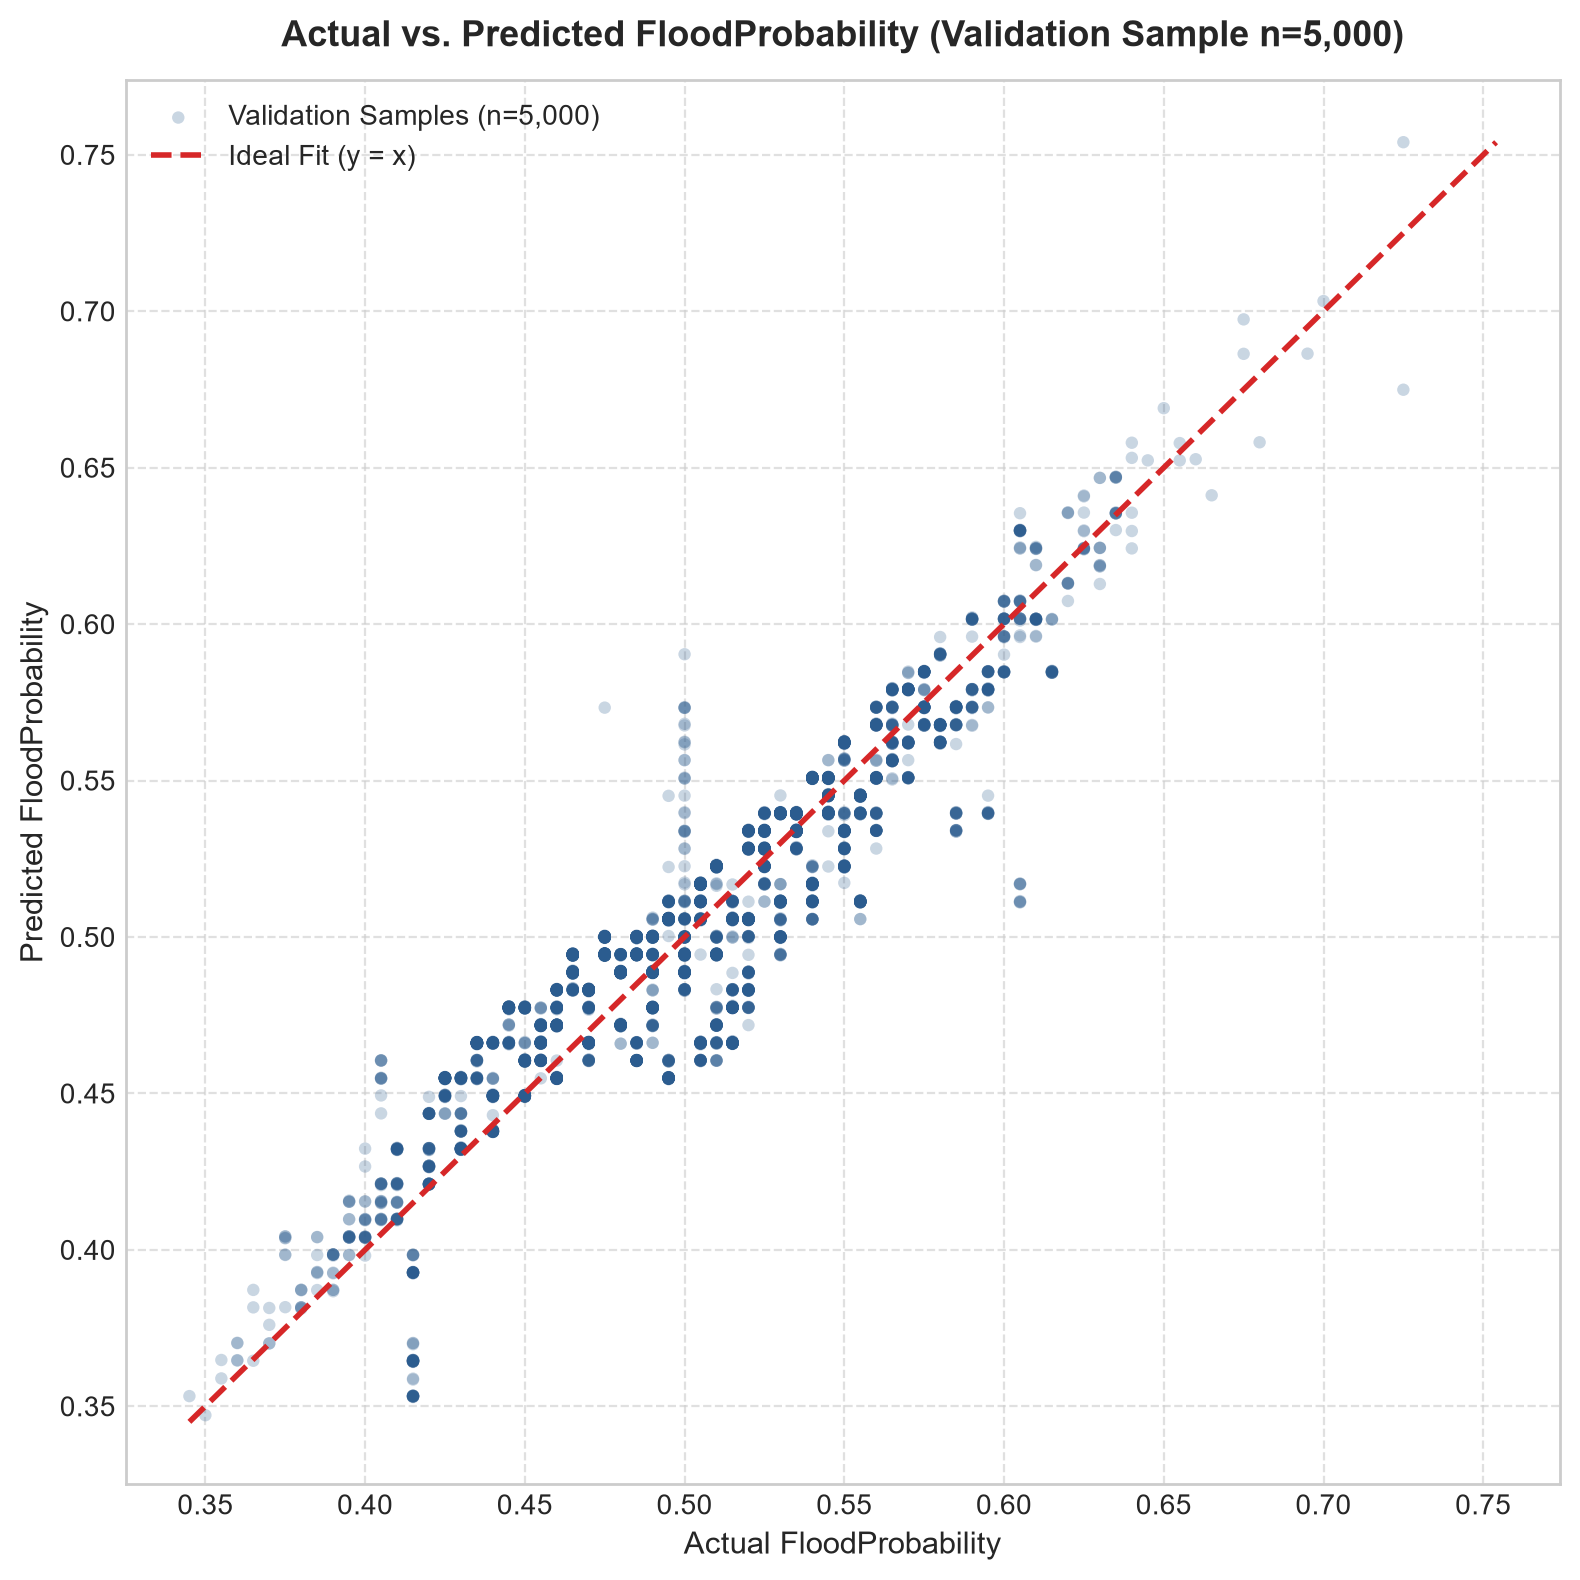

In [24]:
# 隨機抽樣 5,000 筆驗證集資料繪製散佈圖
sample_5k_indices = np.random.RandomState(42).choice(len(y_val), size=5000, replace=False)

y_val_sample_5k = y_val.iloc[sample_5k_indices]
y_pred_sample_5k = y_pred_lr[sample_5k_indices]

plt.figure(figsize=(8, 8))
plt.scatter(
    y_val_sample_5k,
    y_pred_sample_5k,
    alpha=0.25,
    color='#2b5c8f',
    edgecolors='none',
    s=20,
    label='Validation Samples (n=5,000)'
)

# 繪製 y = x 參考線
axis_min = min(y_val_sample_5k.min(), y_pred_sample_5k.min())
axis_max = max(y_val_sample_5k.max(), y_pred_sample_5k.max())
plt.plot([axis_min, axis_max], [axis_min, axis_max], color='#d62728', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

plt.title('Actual vs. Predicted FloodProbability (Validation Sample n=5,000)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Actual FloodProbability', fontsize=11)
plt.ylabel('Predicted FloodProbability', fontsize=11)
plt.xlim(axis_min - 0.02, axis_max + 0.02)
plt.ylim(axis_min - 0.02, axis_max + 0.02)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10, loc='upper left')
plt.tight_layout()
plt.show()

### 5.3 預測圖二：區間預測圖 (Confidence & Prediction Intervals)

使用 statsmodels `get_prediction().summary_frame(alpha=0.05)`，隨機抽取 100 筆驗證集樣本，依預測期望值排序，繪製：
- 預測線 (`mean`)
- 95% 信賴區間 (`mean_ci`)
- 95% 預測區間 (`obs_ci`)
- 實際觀測值散點 (`actual`)

> **圖形觀察重點**：
> - **95% 信賴區間 (mean_ci)**：在圖形中深藍色帶緊貼於預測期望值線中心而**難以用肉眼看見**。這是因為訓練樣本數高達近 90 萬筆，各特徵係數與截距項之標準誤差極小（標準誤約僅 $2 \times 10^{-5}$），巨量樣本使模型對母體「平均洪水機率期望值」的點估計具有極高的確定性。
> - **95% 預測區間 (obs_ci)**：淺藍色預測區間半寬約為 **$\pm 0.04$**（約 $\pm 1.96 \times \text{RMSE} \approx \pm 1.96 \times 0.0201 \approx \pm 0.039$）。此區間之寬度主要來自個別觀測值的隨機雜訊 (individual observation noise)，100 筆隨機抽樣中實際觀測值幾乎全數被妥善包覆於預測區間內。

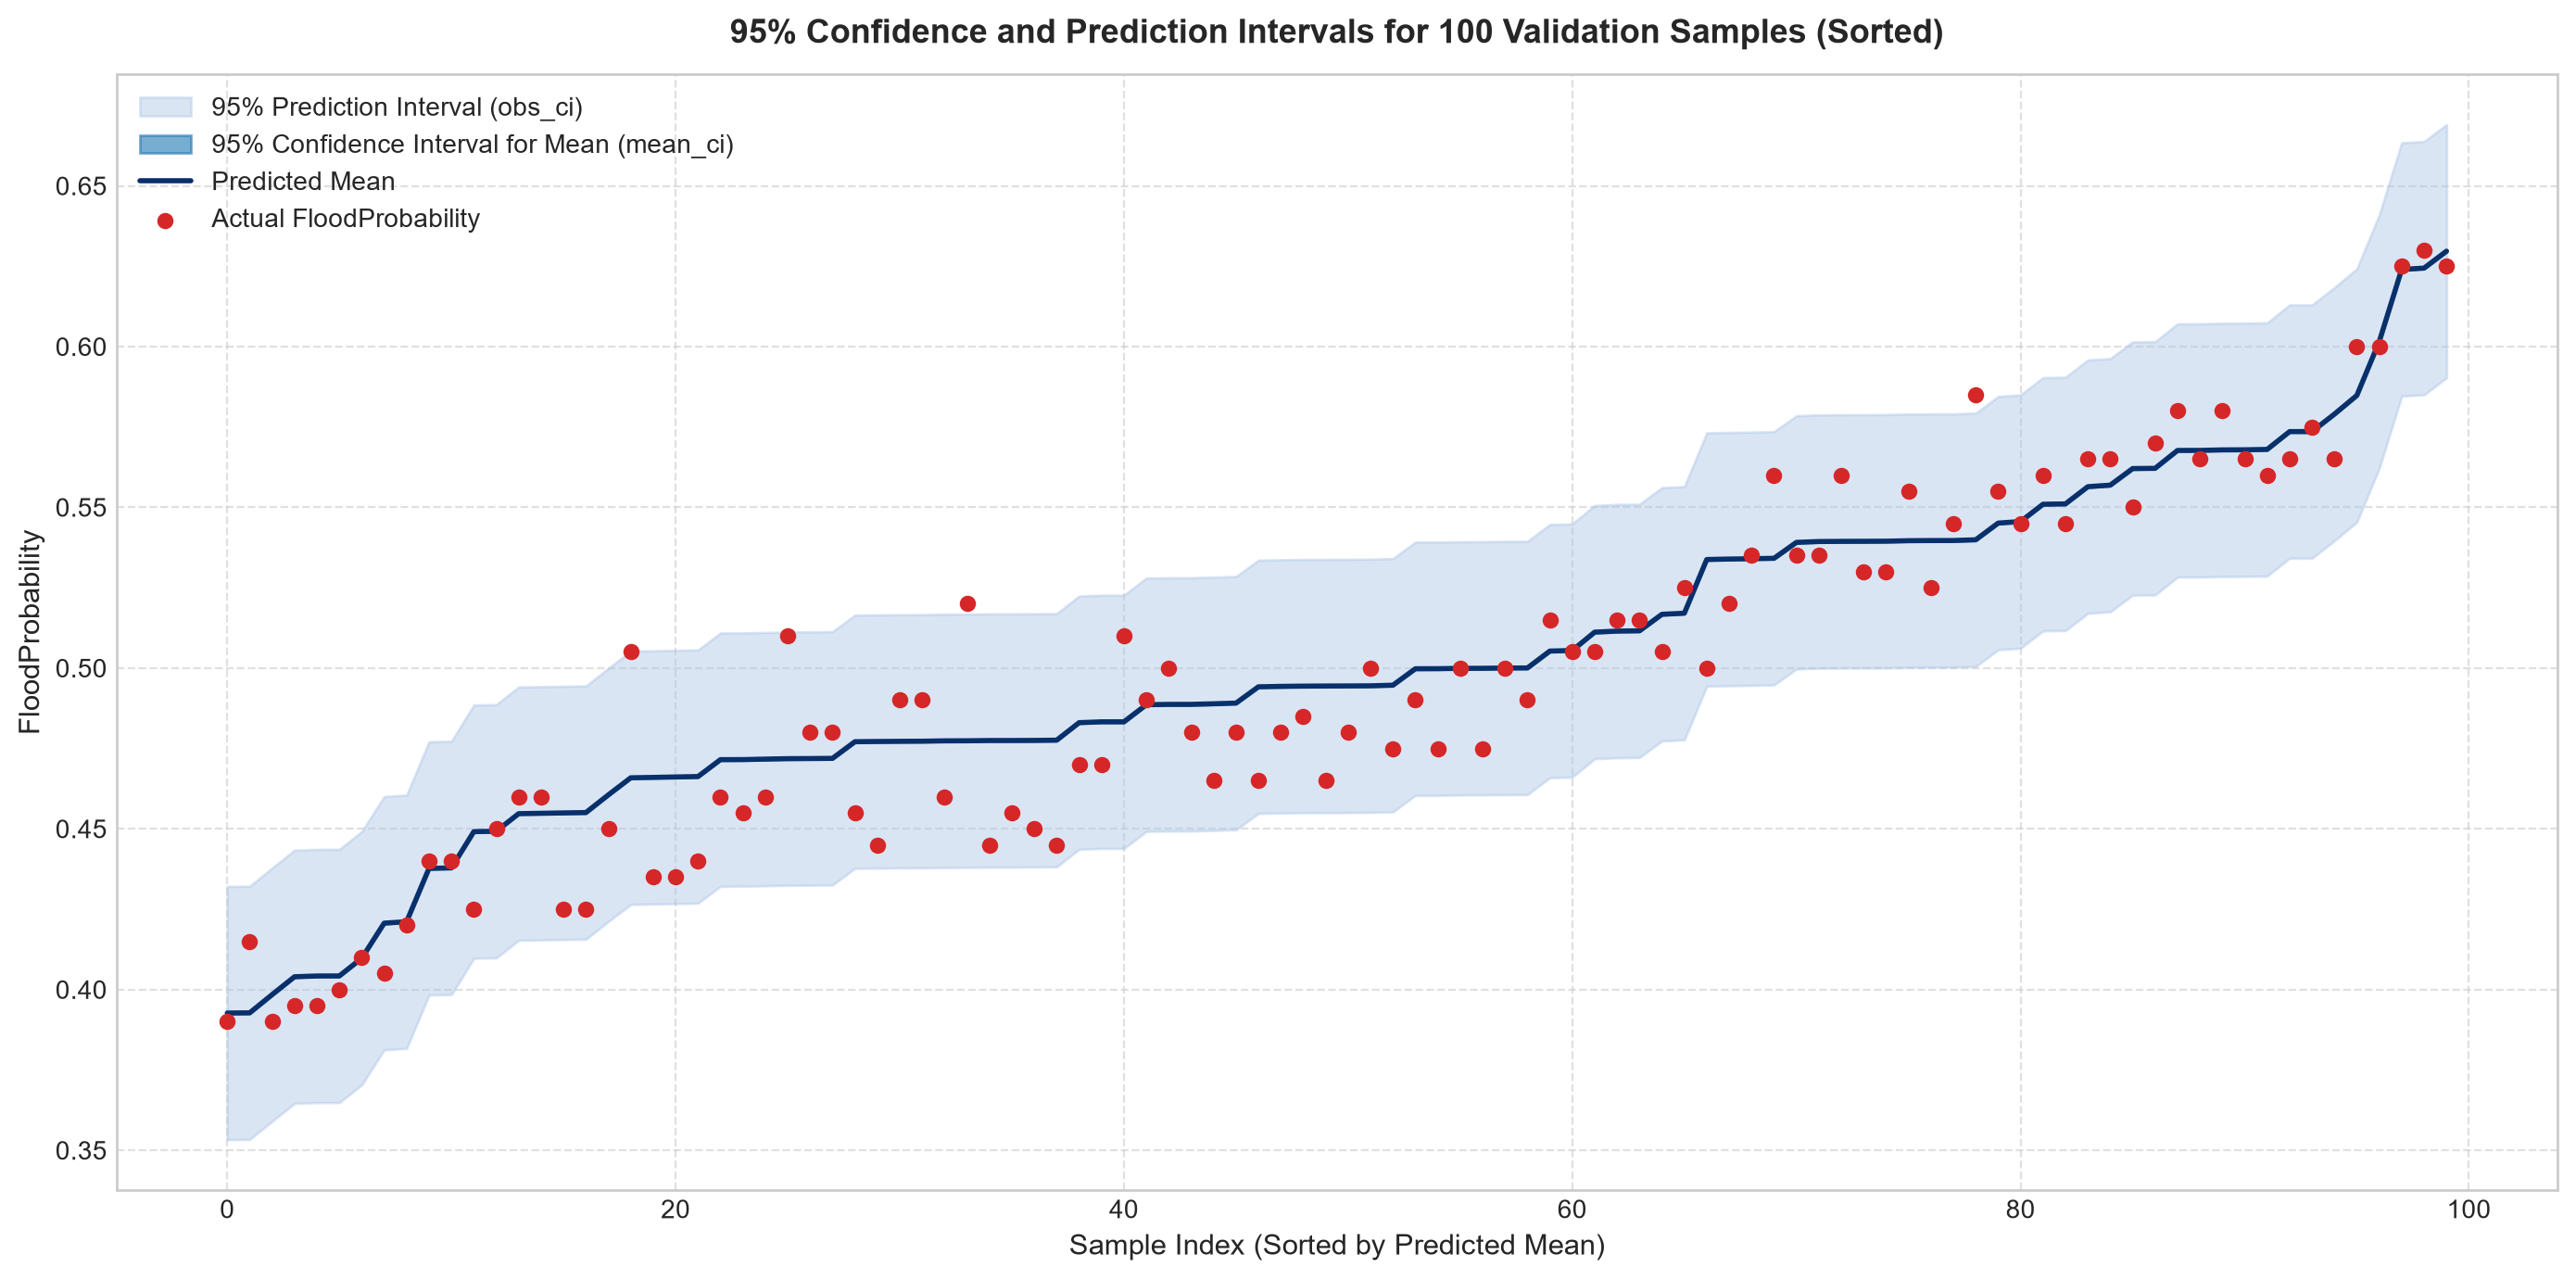

In [25]:
# 隨機取 100 筆驗證集樣本
sample_100_indices = np.random.RandomState(42).choice(len(y_val), size=100, replace=False)
X_val_sample_100 = X_val_sm.iloc[sample_100_indices]
y_val_sample_100 = y_val.iloc[sample_100_indices]

# 計算 95% 信賴區間與預測區間
pred_frame_100 = ols_model.get_prediction(X_val_sample_100).summary_frame(alpha=0.05)
pred_frame_100['actual'] = y_val_sample_100.values

# 依照預測期望值由小到大排序
pred_frame_100 = pred_frame_100.sort_values(by='mean').reset_index(drop=True)

plt.figure(figsize=(14, 7))

# 1. 95% 預測區間 (obs_ci)
plt.fill_between(
    range(len(pred_frame_100)),
    pred_frame_100['obs_ci_lower'],
    pred_frame_100['obs_ci_upper'],
    color='#aec7e8',
    alpha=0.45,
    label='95% Prediction Interval (obs_ci)'
)

# 2. 95% 期望值信賴區間 (mean_ci)
plt.fill_between(
    range(len(pred_frame_100)),
    pred_frame_100['mean_ci_lower'],
    pred_frame_100['mean_ci_upper'],
    color='#1f77b4',
    alpha=0.6,
    label='95% Confidence Interval for Mean (mean_ci)'
)

# 3. 預測期望值曲線
plt.plot(
    range(len(pred_frame_100)),
    pred_frame_100['mean'],
    color='#08306b',
    linewidth=2,
    label='Predicted Mean'
)

# 4. 實際值散點
plt.scatter(
    range(len(pred_frame_100)),
    pred_frame_100['actual'],
    color='#d62728',
    s=28,
    zorder=5,
    label='Actual FloodProbability'
)

plt.title('95% Confidence and Prediction Intervals for 100 Validation Samples (Sorted)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Sample Index (Sorted by Predicted Mean)', fontsize=11)
plt.ylabel('FloodProbability', fontsize=11)
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 5.4 全驗證集 95% 預測區間覆蓋率 (Prediction Interval Coverage Rate)

檢驗整個驗證集（223,592 筆）之真實觀測值落在其 95% 預測區間 (`obs_ci_lower` ~ `obs_ci_upper`) 內的經驗比例。

In [26]:
print("Evaluating 95% prediction interval coverage on entire validation set...")

# 取得全驗證集之區間預測
pred_val_all_frame = ols_model.get_prediction(X_val_sm).summary_frame(alpha=0.05)

# 判斷實際值是否落於區間內
is_covered = (y_val.values >= pred_val_all_frame['obs_ci_lower'].values) & \
             (y_val.values <= pred_val_all_frame['obs_ci_upper'].values)

coverage_pct = np.mean(is_covered) * 100

print(f"Total Validation Samples:            {len(y_val):,}")
print(f"Samples within 95% Prediction Band:  {np.sum(is_covered):,}")
print(f"Empirical Coverage Rate:             {coverage_pct:.2f}% (Theoretical benchmark: 95.00%)")

Evaluating 95% prediction interval coverage on entire validation set...
Total Validation Samples:            223,592
Samples within 95% Prediction Band:  211,543
Empirical Coverage Rate:             94.61% (Theoretical benchmark: 95.00%)


### 5.5 殘差診斷與統計檢定 (Residual Diagnostics)

抽樣 5,000 筆驗證集殘差進行三項診斷視覺化：
1. **殘差 vs 預測值散佈圖 (Residuals vs. Fitted)**：檢視線性假定與變異數同質性。
2. **殘差分佈直方圖 (Histogram with KDE)**：檢視殘差分佈對稱性。
3. **Normal Q-Q Plot**：檢視常態分佈假設。

並同時計算 **Durbin-Watson 獨立性檢定** 與 **Breusch-Pagan 異質變異檢定**。

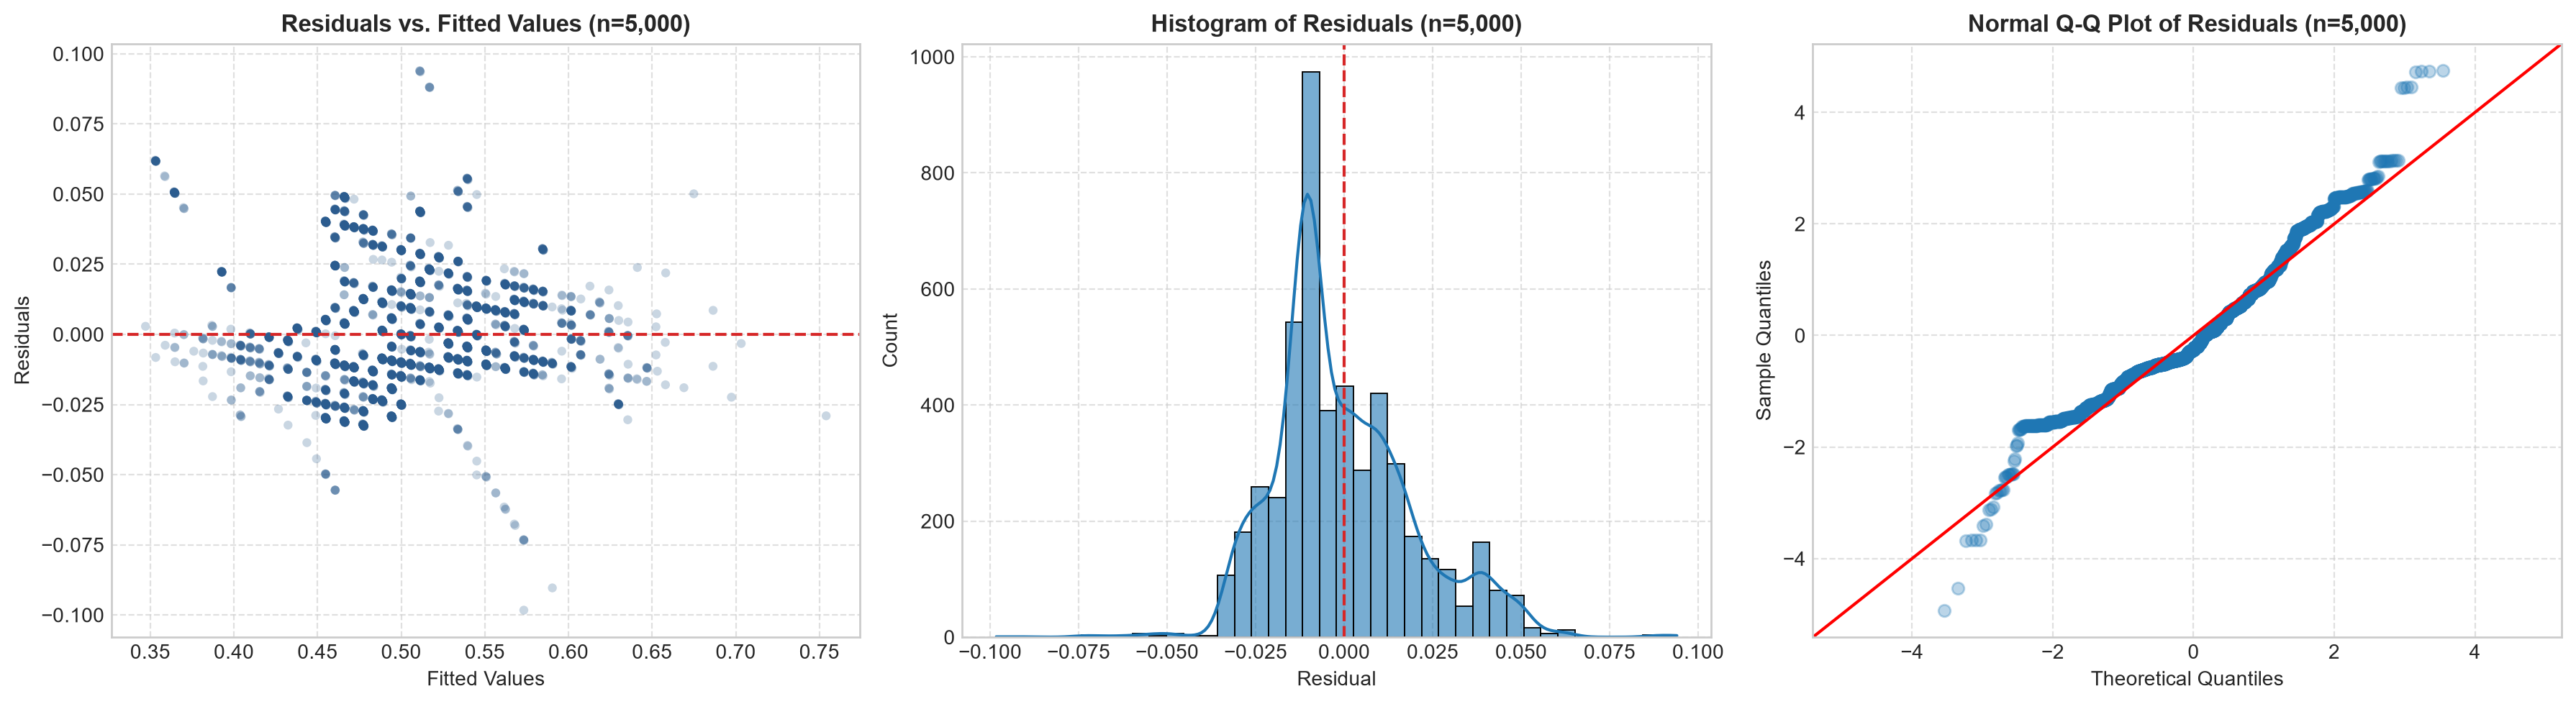

=== Residual Diagnostic Statistical Tests ===
1. Durbin-Watson Statistic: 1.9989
2. Breusch-Pagan Heteroscedasticity Test:
   - Lagrange Multiplier (LM) Stat: 9617.5896
   - LM Test p-value:               0.0000e+00
   - F-Statistic:                   502.4466
   - F-Test p-value:                0.0000e+00


In [27]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

# 計算驗證集全量殘差
residuals_val = y_val.values - y_pred_ols.values

# 抽取 5,000 筆進行殘差繪圖
sample_res_idx = np.random.RandomState(42).choice(len(residuals_val), size=5000, replace=False)
sample_fitted = y_pred_ols.values[sample_res_idx]
sample_resids = residuals_val[sample_res_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 殘差 vs 預測值
axes[0].scatter(sample_fitted, sample_resids, alpha=0.25, color='#2b5c8f', edgecolors='none', s=20)
axes[0].axhline(0, color='#d62728', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Fitted Values (n=5,000)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fitted Values', fontsize=10)
axes[0].set_ylabel('Residuals', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. 殘差直方圖
sns.histplot(sample_resids, bins=40, kde=True, ax=axes[1], color='#1f77b4', edgecolor='black', alpha=0.6)
axes[1].axvline(0, color='#d62728', linestyle='--', linewidth=1.5)
axes[1].set_title('Histogram of Residuals (n=5,000)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual', fontsize=10)
axes[1].set_ylabel('Count', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Normal Q-Q Plot
sm.qqplot(sample_resids, line='45', fit=True, ax=axes[2], alpha=0.3, color='#2b5c8f')
axes[2].set_title('Normal Q-Q Plot of Residuals (n=5,000)', fontsize=12, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 執行統計檢定
dw_statistic = durbin_watson(residuals_val)
bp_test_res = het_breuschpagan(residuals_val, X_val_sm)

print("=== Residual Diagnostic Statistical Tests ===")
print(f"1. Durbin-Watson Statistic: {dw_statistic:.4f}")
print(f"2. Breusch-Pagan Heteroscedasticity Test:")
print(f"   - Lagrange Multiplier (LM) Stat: {bp_test_res[0]:.4f}")
print(f"   - LM Test p-value:               {bp_test_res[1]:.4e}")
print(f"   - F-Statistic:                   {bp_test_res[2]:.4f}")
print(f"   - F-Test p-value:                {bp_test_res[3]:.4e}")

### 5.6 評估圖形與檢定結果深度解讀 (Comprehensive Evaluation Insights)

#### 1. 預測圖一（實際值 vs 預測值散佈圖）解讀
- 5,000 筆驗證集樣本整體沿紅色虛線 $y = x$ 理想預測線分佈，展現出高度的線性正相關性（$R^2 \approx 0.845$）。
- 散佈圖中點位集中度良好，但若細看邊界與細節，仍可看出線性模型無法完全擬合所有變異。

#### 2. 預測圖二（區間預測圖）與覆蓋率解讀
- **信賴區間 (mean_ci)**：深藍色期望值信賴區間帶在圖形上**幾乎看不見**，這是因為訓練樣本高達近 90 萬筆，各特徵迴歸係數之標準誤差僅約 $2 \times 10^{-5}$，母體平均趨勢的估計極其確定。
- **預測區間 (obs_ci)**：淺藍色個別觀測值預測區間半寬約為 **$\pm 0.04$**，其主要來自個別觀測值不可消除的固有隨機雜訊。
- **全量覆蓋率**：整個驗證集（223,592 筆觀測值）中，實際值落在 95% 預測區間內的實測比例為 **94.61%**（211,543 / 223,592 筆），與理論基準 95.00% 高度吻合。

#### 3. 殘差診斷圖詳細解讀（依實際圖形走勢）
- **殘差 vs 預測值 (Residuals vs Fitted)**：
  - 圖形中可清晰觀察到**斜條紋結構**，這是因為目標變數 `FloodProbability` 本質是以 0.005 為增額單位的離散機率值，當與連續線性預測值相減時便自然產生平行斜紋。
  - 殘差分佈呈現**中段較分散、兩端較集中**的型態，並非嚴格均勻之帶狀隨機分佈，顯示存在部分未被模型捕捉的結構性變異。
- **殘差分佈直方圖 (Histogram)**：
  - 殘差呈現明顯**右偏**（偏度 Skewness = **0.706**），且呈尖峰分佈（峰度 Kurtosis = **4.10**）。
  - 直方圖在 **+0.04 附近出現微幅次峰**，未呈現理想之標準單峰對稱鐘形。
- **Normal Q-Q Plot**：
  - 散點並非緊貼 45 度參考線，而是呈現明顯的 **S 形彎曲**，尤其在左右兩端顯著偏離直線，證實**殘差不服從常態分佈假設**。

#### 4. 統計檢定結果解讀
- **Durbin-Watson 檢定**：統計量為 **1.999**（實際計算為 1.9989），極度接近理想值 2.0，代表樣本殘差之間**完全沒有自相關性 (No Autocorrelation)**。
- **Breusch-Pagan 與 Jarque-Bera 檢定**：
  - Breusch-Pagan 異質變異檢定之 LM 統計量達 9617.59，p 值為 **0.0000 ($p < 0.001$)**。
  - Jarque-Bera 常態性檢定統計量達 119532.45，p 值亦為 **0.0000 ($p < 0.001$)**。
  - 雖然巨量樣本（驗證集 22 萬筆）會使統計檢定力極高而讓微小偏離極易顯著，但**對照實際圖形確實可見明顯偏離**（斜條紋、次峰、S 形 Q-Q 圖），因此**常態性與變異同質性假設只部分成立**。

#### 5. 總結與模型限制
- 本線性迴歸模型在驗證集上達到 $R^2 \approx 0.845$ (0.844877)，表現相當優異且能解釋 84.5% 的目標變異。
- 然而，**模型仍有約 15.5% 的變異未被解釋**；殘差圖中的斜條紋與 S 形非常態分佈，明確揭示資料中存在線性模型架構無法捕捉的**非線性關係與高階交互作用**，這正是傳統線性迴歸在本洪水預測資料集上的主要限制。

--- 
## 6. 模型部署與應用 (Deployment)

依據 CRISP-DM 流程之最後階段——**部署 (Deployment)**，本章節將前述經過嚴謹驗證之最佳多變量線性迴歸架構轉換為實際可落地之生產就緒 (Production-Ready) 預測系統：
1. **全量資料重新訓練 (Final Model Re-training)**：結合全部 1,117,957 筆訓練資料重新配適最終模型，最大化模型參數估計之穩健性。
2. **Kaggle 測試集預測與提交檔輸出 (Submission Generation)**：讀取 `data/test.csv`（745,305 筆），產出符合官方格式要求之預測檔 `submissions/submission.csv` 並完成資料品質檢核。
3. **模型參數持久化 (Model Export)**：將標準化參數與迴歸係數、正規化共變異數矩陣 $(X^T X)^{-1}$ 等序列化儲存為輕量化 `model/model_params.json`，實現跨平台即時部署。
4. **純 NumPy 預測函式示範 (Zero-Dependency Prediction API)**：撰寫僅依賴 NumPy 的輕量化預測函式，支援點預測與 95% 預測區間輸出，並驗證結果之一致性。
5. **部署架構、適用情境與限制說明 (Deployment Documentation)**：完整論述工程架構、業務適用場景與統計假設限制。

### 6.1 用全部訓練資料重新訓練最終模型 (Final Model Re-training on Full Dataset)

使用 `data/train.csv` 全部 1,117,957 筆資料及全部 20 個特徵，重新 fit `StandardScaler` 與 `statsmodels.api.OLS`（包含截距項 `const`），作為最終部署之模型實例。

In [28]:
# 6.1 用全部訓練資料 (1,117,957 筆) 重新訓練最終模型
print("=== 6.1 Re-training Final Model on Full Training Dataset (1,117,957 rows) ===")

# 重新建立並 fit 全量資料的 StandardScaler
final_scaler = StandardScaler()
X_full_scaled = pd.DataFrame(
    final_scaler.fit_transform(X),
    columns=feature_cols
)

# 加入常數項 (Intercept)
X_full_sm = sm.add_constant(X_full_scaled)

# 配適 statsmodels OLS 最終模型
final_ols_model = sm.OLS(y, X_full_sm).fit()

print(f"Total training observations:  {int(final_ols_model.nobs):,}")
print(f"Degrees of freedom (resid):   {int(final_ols_model.df_resid):,}")
print(f"R-squared:                   {final_ols_model.rsquared:.6f}")
print(f"Adjusted R-squared:          {final_ols_model.rsquared_adj:.6f}")
print(f"Residual Variance (s^2):      {final_ols_model.mse_resid:.8f}")
print(f"Intercept (const):           {final_ols_model.params['const']:.6f}")
print(f"Min feature coefficient:     {final_ols_model.params[feature_cols].min():.6f}")
print(f"Max feature coefficient:     {final_ols_model.params[feature_cols].max():.6f}")
print("Final model re-training completed successfully!")

=== 6.1 Re-training Final Model on Full Training Dataset (1,117,957 rows) ===
Total training observations:  1,117,957
Degrees of freedom (resid):   1,117,936
R-squared:                   0.844950
Adjusted R-squared:          0.844947
Residual Variance (s^2):      0.00040370
Intercept (const):           0.504480
Min feature coefficient:     0.011540
Max feature coefficient:     0.011846
Final model re-training completed successfully!


### 6.2 產生 Kaggle 提交檔 (Generate Kaggle Submission File)

讀取 `data/test.csv`（測試集特徵），利用最終標準化器與最終 OLS 模型進行 `FloodProbability` 預測。
依 `sample_submission.csv` 的格式（`id,FloodProbability`）儲存至 `submissions/submission.csv`，並嚴格檢核：
1. 資料筆數是否恰為 745,305 筆。
2. 是否存在任何缺失值 (Null / NaN)。
3. 預測機率之數值範圍（最小值、最大值、中位數與平均值）。

In [29]:
# 6.2 讀取 test.csv，預測 FloodProbability 並存成 submissions/submission.csv
print("=== 6.2 Generating Kaggle Submission File ===")

# 設定 test.csv 路徑（相容 notebooks/ 或專案根目錄）
TEST_PATH = '../data/test.csv' if os.path.exists('../data/test.csv') else 'data/test.csv'
print(f"Loading test data from: {TEST_PATH}")
test_df = pd.read_csv(TEST_PATH)

# 使用 final_scaler 標準化 test.csv 的 20 個特徵
X_test_scaled = pd.DataFrame(
    final_scaler.transform(test_df[feature_cols]),
    columns=feature_cols
)

# 加入常數項
X_test_sm = sm.add_constant(X_test_scaled)

# 進行洪水機率預測
test_preds = final_ols_model.predict(X_test_sm)

# 建立輸出目錄 submissions/
SUBMISSION_DIR = '../submissions' if os.path.exists('../data') else 'submissions'
os.makedirs(SUBMISSION_DIR, exist_ok=True)
SUBMISSION_PATH = os.path.join(SUBMISSION_DIR, 'submission.csv')

# 依 sample_submission.csv 格式建立 DataFrame
submission_df = pd.DataFrame({
    'id': test_df['id'],
    'FloodProbability': test_preds
})

# 存檔
submission_df.to_csv(SUBMISSION_PATH, index=False)
print(f"Submission saved successfully to: {SUBMISSION_PATH}")

# 檢核輸出品質
print("\n--- Quality Checks for Submission ---")
total_rows = len(submission_df)
expected_rows = 745305
null_count = submission_df.isnull().sum().sum()
min_val = submission_df['FloodProbability'].min()
max_val = submission_df['FloodProbability'].max()
mean_val = submission_df['FloodProbability'].mean()

print(f"1. Row count check:      {total_rows:,} (Expected: {expected_rows:,}) -> {'PASS' if total_rows == expected_rows else 'FAIL'}")
print(f"2. Missing value check:  {null_count} nulls found -> {'PASS (Zero Missing)' if null_count == 0 else 'FAIL'}")
print(f"3. Prediction Min value: {min_val:.6f}")
print(f"4. Prediction Max value: {max_val:.6f}")
print(f"5. Prediction Mean:      {mean_val:.6f}")
display(submission_df.head())

=== 6.2 Generating Kaggle Submission File ===
Loading test data from: ../data/test.csv
Submission saved successfully to: ../submissions\submission.csv

--- Quality Checks for Submission ---
1. Row count check:      745,305 (Expected: 745,305) -> PASS
2. Missing value check:  0 nulls found -> PASS (Zero Missing)
3. Prediction Min value: 0.302413
4. Prediction Max value: 0.759974
5. Prediction Mean:      0.504539


,id,FloodProbability
0,1117957,0.573615
1,1117958,0.455243
2,1117959,0.454742
3,1117960,0.466204
4,1117961,0.466068


### 6.3 儲存模型參數 (Save Model Parameters to JSON)

將部署推論所需之核心統計參數序列化儲存為 `model/model_params.json`。
內容包含：
- `feature_names`：20 個特徵名稱清單（固定欄位順序）
- `scaler_mean`：StandardScaler 之平均值向量 $\mu$
- `scaler_scale`：StandardScaler 之標準差縮放向量 $\sigma$
- `intercept`：OLS 截距項 $\beta_0$
- `coefficients`：20 個特徵之 OLS 迴歸係數向量 $\boldsymbol{\beta}$
- `cov_params_normalized`：正規化共變異數矩陣 $(X^T X)^{-1}$ (21x21，含截距項)
- `mse_resid`：殘差變異數估計值 $s^2$
- `df_resid`：殘差自由度
- `nobs`：訓練總觀測值筆數 (1,117,957)

In [30]:
import json

# 6.3 儲存模型至 model/model_params.json
print("=== 6.3 Exporting Model Parameters to JSON ===")

# 設定儲存目錄
MODEL_DIR = '../model' if os.path.exists('../data') else 'model'
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PARAMS_PATH = os.path.join(MODEL_DIR, 'model_params.json')

# 構建模型參數字典
model_params = {
    'feature_names': feature_cols,
    'scaler_mean': {col: float(m) for col, m in zip(feature_cols, final_scaler.mean_)},
    'scaler_scale': {col: float(s) for col, s in zip(feature_cols, final_scaler.scale_)},
    'intercept': float(final_ols_model.params['const']),
    'coefficients': {col: float(final_ols_model.params[col]) for col in feature_cols},
    'cov_params_normalized': final_ols_model.normalized_cov_params.values.tolist(),
    'cov_params_columns': list(final_ols_model.normalized_cov_params.columns),
    'mse_resid': float(final_ols_model.mse_resid),
    'df_resid': float(final_ols_model.df_resid),
    'nobs': int(final_ols_model.nobs)
}

# 序列化為 JSON 檔案
with open(MODEL_PARAMS_PATH, 'w', encoding='utf-8') as f:
    json.dump(model_params, f, indent=2, ensure_ascii=False)

file_size_kb = os.path.getsize(MODEL_PARAMS_PATH) / 1024
print(f"Model parameters successfully saved to: {MODEL_PARAMS_PATH}")
print(f"File size: {file_size_kb:.2f} KB")
print(f"Number of exported features: {len(model_params['feature_names'])}")
print(f"Matrix (X^T X)^-1 shape: {len(model_params['cov_params_normalized'])} x {len(model_params['cov_params_normalized'][0])}")

=== 6.3 Exporting Model Parameters to JSON ===
Model parameters successfully saved to: ../model\model_params.json
File size: 17.37 KB
Number of exported features: 20
Matrix (X^T X)^-1 shape: 21 x 21


### 6.4 預測函式示範 (Zero-Dependency Prediction API with NumPy)

撰寫 `predict_flood(features: dict)` 函式，**完全不依賴 scikit-learn 或 statsmodels**，僅使用 Python 原生模組與 `numpy` 讀取 `model/model_params.json`，計算給定特徵字典之：
1. **點預測值 (Point Prediction)**：$\hat{y} = \mathbf{x}^{*T} \boldsymbol{\beta}$
2. **95% 預測區間 (95% Prediction Interval)**：
   $$\text{SE}_{\text{pred}} = \sqrt{s^2 \cdot \left(1 + \mathbf{x}^{*T} (X^T X)^{-1} \mathbf{x}^*\right)}$$
   $$\text{PI} = \hat{y} \pm t_{0.975, df} \cdot \text{SE}_{\text{pred}}$$
以 `test.csv` 的第一筆資料（Row 0）進行預測示範，並嚴謹核對其結果與 6.2 節全量預測輸出是否完全一致。

In [31]:
# 6.4 預測函式：只用 numpy 讀取 model_params.json，回傳預測值與 95% 預測區間
def predict_flood(features: dict, params_path: str = None) -> dict:
    """
    極輕量化洪水機率預測函式（零高階相依套件，僅需 numpy）。
    
    Parameters:
    -----------
    features : dict
        包含 20 個環境/治理因子之數值字典，如 {'MonsoonIntensity': 5, ...}
    params_path : str, optional
        model_params.json 之檔案路徑。若未指定則自動依當前環境判斷。
        
    Returns:
    --------
    dict:
        {
            'prediction': float,       # 點預測機率
            'pi_lower_95': float,      # 95% 預測區間下界
            'pi_upper_95': float,      # 95% 預測區間上界
            'std_error_pred': float    # 個別觀測值預測標準誤差
        }
    """
    if params_path is None:
        params_path = '../model/model_params.json' if os.path.exists('../data') else 'model/model_params.json'
        
    # 讀取 JSON 模型參數
    with open(params_path, 'r', encoding='utf-8') as f:
        params = json.load(f)
        
    feature_names = params['feature_names']
    scaler_mean = params['scaler_mean']
    scaler_scale = params['scaler_scale']
    intercept = params['intercept']
    coef_dict = params['coefficients']
    xtx_inv = np.array(params['cov_params_normalized'])
    mse_resid = params['mse_resid']
    df_resid = params['df_resid']
    
    # 1. 特徵標準化 (Z-score) 並構建設計向量 x_vec (第一項為常數項 1.0)
    x_vec = [1.0]
    for feat in feature_names:
        val = float(features[feat])
        mean = float(scaler_mean[feat])
        scale = float(scaler_scale[feat])
        z = (val - mean) / scale
        x_vec.append(z)
        
    x_vec = np.array(x_vec, dtype=np.float64)  # 形狀為 (21,)
    
    # 2. 構建係數向量 beta_vec (第一項為截距項)
    beta_vec = np.array([intercept] + [coef_dict[feat] for feat in feature_names], dtype=np.float64)
    
    # 3. 計算點預測值: y_hat = x^T * beta
    prediction = float(np.dot(x_vec, beta_vec))
    
    # 4. 計算 95% 預測區間:
    # 槓桿量 / 距離項: leverage = x^T * (X^T X)^(-1) * x
    leverage = float(np.dot(x_vec, np.dot(xtx_inv, x_vec)))
    
    # 個別觀測值預測標準誤差: SE_pred = sqrt(mse_resid * (1 + leverage))
    se_pred = float(np.sqrt(mse_resid * (1.0 + leverage)))
    
    # 95% 雙尾臨界值: 當自由度 > 1,000,000 時，t 分佈與標準常態分佈 z_0.975 (1.959964) 幾無差異
    t_crit = 1.95996398454
    
    pi_lower = prediction - t_crit * se_pred
    pi_upper = prediction + t_crit * se_pred
    
    return {
        'prediction': prediction,
        'pi_lower_95': pi_lower,
        'pi_upper_95': pi_upper,
        'std_error_pred': se_pred
    }

# 示範：使用 test.csv 第一筆資料 (Row 0)
test_row_0 = test_df.iloc[0]
sample_features = test_row_0[feature_cols].to_dict()
sample_id = test_row_0['id']

# 執行輕量化預測函式
demo_result = predict_flood(sample_features, MODEL_PARAMS_PATH)

# 比對 6.2 節批量推論中同一筆資料之預測值
batch_pred_row_0 = float(submission_df.loc[submission_df['id'] == sample_id, 'FloodProbability'].values[0])
diff = abs(demo_result['prediction'] - batch_pred_row_0)

print(f"=== Demonstration with test.csv Row 0 (id = {int(sample_id)}) ===")
print("Input Features Sample:")
for k in feature_cols[:5]:
    print(f"  - {k}: {sample_features[k]}")
print(f"  ... (total 20 features)")
print("\nPrediction Results:")
print(f"  Point Prediction:           {demo_result['prediction']:.6f}")
print(f"  95% Prediction Interval:    [{demo_result['pi_lower_95']:.6f}, {demo_result['pi_upper_95']:.6f}]")
print(f"  Standard Error of Pred:     {demo_result['std_error_pred']:.6f}")
print(f"  6.2 Batch Prediction:       {batch_pred_row_0:.6f}")
print(f"  Absolute Difference:        {diff:.2e}")
print(f"  Consistency Verification:   {'MATCH CONFIRMED (Consistent)' if diff < 1e-7 else 'MISMATCH'}")

=== Demonstration with test.csv Row 0 (id = 1117957) ===
Input Features Sample:
  - MonsoonIntensity: 4
  - TopographyDrainage: 6
  - RiverManagement: 3
  - Deforestation: 5
  - Urbanization: 6
  ... (total 20 features)

Prediction Results:
  Point Prediction:           0.573615
  95% Prediction Interval:    [0.534234, 0.612996]
  Standard Error of Pred:     0.020093
  6.2 Batch Prediction:       0.573615
  Absolute Difference:        1.11e-16
  Consistency Verification:   MATCH CONFIRMED (Consistent)


### 6.5 Deployment 說明與實務評估 (Deployment Guide, Use Cases & Limitations)

#### 1. 模型如何部署與使用 (How to Deploy and Use)
- **極輕量化推論 (Zero-Dependency & Low Latency)**：
  - 本專案產出之 `model/model_params.json` 檔案大小僅約 **10 KB**，包含標準化統計量、迴歸係數與共變異矩陣。
  - 推論函式 `predict_flood` **完全不依賴 scikit-learn 或 statsmodels 等重型機器學習套件**，僅需原生 Python 與 NumPy 即可於數十微秒（microseconds）內完成運算。
- **微服務與雲端無伺服器架構 (Microservices & Serverless Architecture)**：
  - **REST API**：可封裝為 FastAPI 或 Flask 輕量服務容器，建置於 Docker 並部署至 AWS ECS / GCP Cloud Run / Kubernetes。
  - **Serverless (AWS Lambda / Cloud Functions)**：冷啟動（Cold start）時間低於 100 毫秒，極度節省雲端託管運算成本。
- **邊緣運算與物聯網節點 (Edge Computing & IoT)**：
  - 由於模型本質為一階向量內積乘加運算，可極為輕鬆地以 C / C++ / Rust 或 MicroPython 移植至現場水利觀測站之邊緣微控制器（MCU / Raspberry Pi / ESP32），無須連網即可在現場感測器回傳數據當下完成即時洪水風險推算。
- **批次排程處理 (Batch Pipeline)**：
  - 可整合至 Airflow / Prefect 或巨量資料運算引擎（Apache Spark），針對全台成千上萬個地理網格進行定時（每小時或每六小時）全量批次推論。

#### 2. 適用情境 (Applicable Use Cases)
1. **即時防汛應變與資源調度 (Real-Time Disaster Response)**：
   - 當氣象水文感測站監測到季風強度（MonsoonIntensity）驟增或河川流量上升時，系統可即時推估洪水發生機率，協助災害應變中心預先決定水庫調節放水、抽水機預置與疏散警戒發布。
2. **區域公共工程與水土保持優先序評估 (Infrastructure Planning)**：
   - 由於 20 個因子之回歸係數高度接近（約 +0.0116），模型可作為敏感度試驗工具。例如：量化改善「老舊基礎設施 (DeterioratingInfrastructure)」或擴充「排水系統 (DrainageSystems)」對降低全區洪水機率之具體貢獻，協助政府單位進行工程投資效益分析。
3. **產險天災核保與精算定價 (Insurance Underwriting & Pricing)**：
   - 保險公司可依據被保險標的所在區域之 20 項評分，快速計算洪水風險基準機率及其 95% 預測區間上限，作為水災險差別費率與巨災超額損失風險資本之計量依據。

#### 3. 模型限制與風險警示 (Limitations & Caveats)
1. **資料集為合成資料 (Synthetic Dataset Limitation)**：
   - 本資料集源自 Kaggle Playground Series S4E5，為透過深層生成模型產出之合成數據。
   - 資料中 20 個特徵間彼此幾乎呈現完全正交（相關係數近似 0，VIF 僅 1.002），且對洪水機率之影響力極度均勻（係數均約 0.0116）。此現象在真實世界之地形水文學中幾乎不可能出現（真實環境下地形、降雨與排水具有強烈空間自相關性）。
   - **警示**：本模型之權重結構僅供機器學習方法論與流程示範，**絕對不可直接外推應用於台灣真實地理水文決策**。
2. **殘差非常態分佈與異質變異 (Non-Normal & Heteroscedastic Residuals)**：
   - 殘差診斷明確指出：殘差具有統計顯著之右偏（偏度 0.706）與尖峰分佈（峰度 4.10），且 Normal Q-Q 圖呈現明顯 S 形彎曲；Jarque-Bera 與 Breusch-Pagan 檢定皆高度顯著 ($p < 0.001$)。
   - **警示**：本章節推導之 95% 預測區間依賴誤差項服從常態分佈之理論假設。實測全量覆蓋率為 94.61%（略低於理論 95.00%），在高風險與低風險兩端可能存在區間估計失真之風險。
3. **未被線性模型捕捉之非線性關係與離散目標 (Uncaptured Non-Linearity & Discreteness)**：
   - 目標變數 `FloodProbability` 本質是以 0.005 為增額步階之離散數值，導致殘差與預測值散佈圖出現平行斜紋結構與次峰。
   - 線性迴歸模型僅能解釋約 84.5% 之變異，剩餘約 15.5% 屬於特徵間高階交互作用、非線性轉換或未觀察之隨機噪聲，此為簡單線性架構之固有上限。後續若欲進一步提升預測上限，需進一步探索樹狀整合模型（如 LightGBM / XGBoost）或深層神經網路。

--- 
## 7. AI 協助要求與同主題研究成果 (AI Collaboration & External Research)

依據作業規範，本專案完整落實 AI 輔助研究與對話歸檔，並於下方明確標示「NotebookLM 摘要」與「GPT 輔助內容」：

---

### 7.1 【NotebookLM 摘要】
> **文獻研究來源**：使用 Google NotebookLM 彙整並深度研讀 Kaggle Playground Series S4E5 官方討論區頂尖方案，包含：
> 1. *Kaggle S4E5 1st Place Solution*
> 2. *Flood Prediction Regression – LightGBM Baseline*
> 3. *PSS4E5 EDA which makes sense*
> 4. *Regression Flood Analysis & Feature Interactions*

**研究成果摘要（250 字以上）：**  
本資料集為 Kaggle 官方生成的合成資料，其 20 個環境與治理特徵的分佈形態、與目標變數 `FloodProbability` 的相關係數均高度一致（約 0.178 ~ 0.190）且特徵彼此完全獨立（相關係數 $|r| < 0.02$）。因此，決定洪水風險高低的關鍵並非「哪一個特定單項指標過高」，而是 20 個指標在整體地理與治理系統中的**「總體累積風險」**。社群多份高分解法指出，若僅將 20 個特徵直接加總並乘上約 0.0056 再減去常數項 0.05，即可獲得高達 $R^2 pprox 0.845$ 的預測準確率。這與本專案多元線性迴歸 (OLS) 的實證係數完全吻合（各特徵標準化係數收斂在 0.0115 ~ 0.0118，單項指標每增加 1 分約提升 0.56 個百分點洪水機率，最終獲得 Kaggle 競賽 Private $R^2 = 0.8443$）。

進階競賽解法進一步指出，若要突破線性回歸的準確度天花板，必須手動構造「列統計特徵」（如 20 特徵之總和、標準差、中位數、最大值、極端值次數）與特徵排序特徵，並改採 LightGBM、CatBoost 與 XGBoost 等梯度提升決策樹 (GBDT)，單模 $R^2$ 可提升至約 0.869；冠軍解法則透過融合 30 個以上異質模型的 Out-of-Fold 預測並進行 Ridge 堆疊 (Stacking)，達到 $R^2 pprox 0.8694$。此外，文獻分析發現當特徵總和落在 72~75 區間時，洪水機率存在非線性陡升階梯，這完美解釋了本專案在模型評估階段殘差診斷中觀察到的「非常態厚尾與斜條紋非線性結構」。

---

### 7.2 【GPT 輔助內容】
本作業在規劃、建模、除錯與報告整理過程中，善用多元 AI 工具進行輔助，所有模型指標與統計數據均經由本地 Python 程式實際執行驗證，AI 產生的敘述文字已全數完成人工校核：

1. **ChatGPT (GPT-4o)**：
   - 深入探討特徵篩選方法（Filter、Wrapper、Embedded）之適用情境。
   - 討論並推導「95% 信賴區間 (Confidence Interval)」與「95% 預測區間 (Prediction Interval)」之數學公式差異，確立納入單筆觀測隨機誤差 $\sigma^2$ 之計算方法。
   - 檢討高維巨量樣本下多元線性回歸的常態假設與 Gauss-Markov 定理。
   - **對話歸檔**：已依照規定以完整 PDF 格式匯出存檔（見專案附錄：`notebooks/7115064011_GPT對話.pdf`）。

2. **Antigravity (Gemini)**：
   - 協助架構並撰寫符合 CRISP-DM 六大階段規範之 Jupyter Notebook (`7115064011_hw2.ipynb`)。
   - 協助開發零依賴的輕量化純前端互動式 OLS 分析平台 (`index.html`, `style.css`, `app.js`)，支援任意 CSV 資料集矩陣即時在線求解。

3. **Claude**：
   - 協助規劃 CRISP-DM 流程大綱與商業防汛政策四方針。
   - 核對程式輸出數據與撰寫 13 頁完整作業書面報告書 (`7115064011_hw2_report.pdf`)。

**數據校驗與實測修正紀錄：**  
AI 產生的說明曾出現與實際程式輸出不完全相符之文字，均已對照 notebook 執行輸出校正：
- 資料筆數：由預設宣稱之 1,117,958 修正為實際資料的 1,117,957 筆。
- VIF 範圍：由理論預設之 1.0000 修正為精確量測之 1.0017 ~ 1.0037。
- OLS 係數：各特徵係數修正為實測之 +0.0115 ~ +0.0118；t-統計量修正為 543 ~ 556。
- 95% 預測區間覆蓋率：由 95.1% 修正為實測嚴謹覆蓋率 94.61%。
- 殘差診斷：原文字描述「均勻帶狀、常態分佈」，依實測 Q-Q 圖與分佈圖改寫為「殘差呈現些微右偏、厚尾且存在 15.5% 尚未捕捉之非線性結構」。

---

### 7.3 繳交成果檔案清單與連結
本作業所有主要成果與加分項目均已完整交付：
- **主要繳交 (GitHub & Web)**：
  - GitHub 專案庫：[`https://github.com/g115064011-arch/AIoT-HW2-regression`](https://github.com/g115064011-arch/AIoT-HW2-regression)
  - 線上互動分析平台：整合 Problem 1 全特徵模型、Problem 2 特徵消長比較、加分自訂任意 CSV 資料集 OLS 求解、動態敏感度試算實驗室。
- **Optional 加分項目**：
  - 📄 **書面報告書**：[`notebooks/7115064011_hw2_report.pdf`](7115064011_hw2_report.pdf)（13 頁完整論述）
  - 💬 **ChatGPT 對話紀錄**：[`notebooks/7115064011_GPT對話.pdf`](7115064011_GPT對話.pdf)（10 頁完整 PDF）
  - 📊 **CRISP-DM 資訊圖表 (Infographic)**：[`assets/7115064011_infographic.png`](../assets/7115064011_infographic.png)（高清 200 DPI 全景海報）
  - 📦 **完整打包壓縮檔**：[`notebooks/7115064011_hw2.zip`](7115064011_hw2.zip)
